# LeNet Quantization, Pruning and Hardware Weight Export

**Matin Firoozbakht**  
GitHub: [@matinfirooz](https://github.com/matinfirooz)

Complete answers to the supplied HW4 specification, with genuine executed outputs, the complete source, all precision results and hardware-style figures. Every reported accuracy uses all **10,000 official Fashion-MNIST test images**.

For execution, keep this notebook inside the extracted `HW4_Matin_Firoozbakht` project. The embedded outputs and source listings can be read directly. The supplied data and models allow offline evaluation. Default execution validates evidence, recomputes FP32 evaluation, demonstrates the manual methods, decodes packed weights and runs all 26 tests.


In [1]:
from pathlib import Path
import os, sys, json, re, subprocess, importlib.metadata
os.environ.setdefault('OPENBLAS_NUM_THREADS','1')
ROOT = Path.cwd()
assert (ROOT/'software/quantization.py').exists(), 'Run inside the extracted project directory.'
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
RETRAIN = False
RECOMPUTE_EXPERIMENTS = False
RUN_TESTS = True

if RETRAIN: RECOMPUTE_EXPERIMENTS = True
if RECOMPUTE_EXPERIMENTS:
    steps = (['train.py'] if RETRAIN else []) + ['run_manual.py','run_pytorch.py','run_pruning.py','benchmark.py','qualify_packed.py','render_figures.py']
    for step in steps:
        subprocess.run([sys.executable, str(ROOT/'scripts'/step)], cwd=ROOT, check=True)
    subprocess.run([sys.executable,'-m','unittest','discover','-s','tests','-v'], cwd=ROOT, check=True)
    subprocess.run([sys.executable,'scripts/verify_evidence.py','--record'], cwd=ROOT, check=True)
    subprocess.run([sys.executable,'scripts/write_documentation.py'], cwd=ROOT, check=True)

import numpy as np
import pandas as pd
import torch
from IPython.display import display, Markdown, Image, Code
from software.evidence import validate
report = validate(ROOT)
assert report['status']=='passed', report
print('Author: Matin Firoozbakht | GitHub: @matinfirooz')
print('Saved experiment evidence:', report)
print('Python',sys.version.split()[0], '| NumPy',np.__version__, '| PyTorch',torch.__version__)
torch.set_num_threads(4)


Author: Matin Firoozbakht | GitHub: @matinfirooz
Saved experiment evidence: {'status': 'passed', 'checked_files': 373, 'changed_or_missing': [], 'unrecorded_files': []}
Python 3.12.14 | NumPy 2.3.5 | PyTorch 2.5.1+cpu


In [2]:
def answer_section(number):
    text=(ROOT/'COMPLETE_ANSWERS.md').read_text()
    match=re.search(rf'(?m)^## {number}\.',text)
    assert match, number
    next_section=re.search(r'(?m)^## \d+\.',text[match.end():])
    end=match.end()+next_section.start() if next_section else len(text)
    display(Markdown(text[match.start():end]))
def figure(relative):
    display(Image(filename=str(ROOT/relative)))


In [3]:
answer_section(1)

## 1. Purpose and memory calculation

Quantization represents continuous parameters and activations using a finite grid. The main direct benefit in this project is a smaller parameter payload. Native integer kernels can also change execution cost, while Q/DQ simulation measures numerical effects with floating-point operators. Pruning removes selected connections or channels; a suitable sparse format or actual shape reduction is needed to turn zeros into storage or compute reductions.

For 175 billion parameters at 32 bits:

$$M = 175\times10^9\times32/8 = 700\times10^9\ \text{bytes}.$$

This is **700 GB decimal**, approximately **651.93 GiB**, before activation buffers, optimizer state and runtime metadata. Ideal FP16 and INT8 parameter-only storage would be 350 GB and 175 GB, respectively. Scales, zero-points and bias policies add overhead.



In [4]:
answer_section(2)

## 2. Manual symmetric quantization

For b bits, the assignment uses a narrow signed range:

$$Q=2^{b-1}-1,\quad q_{\min}=-Q,\quad q_{\max}=Q,$$
$$s=\max_i |x_i|/Q,\quad z=0,$$
$$q=\operatorname{clip}(\operatorname{round}(x/s),-Q,Q),\quad \hat{x}=sq.$$

All-zero tensors use scale 1 and code 0. This implementation uses nearest-even rounding and saturates explicitly. In the absence of clipping, nearest-neighbor reconstruction error is at most half a scale step. The often-used estimate MSE ≈ s²/12 additionally assumes a roughly uniform quantization residual; it is not a guarantee for these weights.

At two bits the narrow symmetric range is **−1 to +1**, so it has three active levels. A two-bit container has four bit patterns; the −2 code is unused. This distinction matters when interpreting the very poor two-bit results.



In [5]:
answer_section(3)

## 3. Two asymmetric formulations

### 3.1 Literal shifted endpoint formula

The supplied PDF states:

$$s=(x_{\max}-x_{\min})/(2^b-1),$$
$$q=\operatorname{clip}(\operatorname{round}((x-x_{\min})/s),0,2^b-1),$$
$$\hat{x}=sq+x_{\min}.$$

This uses a real-valued offset. It preserves the two endpoints but generally cannot make a floating-point zero exactly representable with an integer zero-point. Constant tensors use scale 1, code 0 and their constant value as the offset.

### 3.2 Hardware affine grid with an integer zero-point

Use a range that includes zero:

$$l=\min(x_{\min},0),\quad h=\max(x_{\max},0),$$
$$s=(h-l)/(2^b-1),\quad z=\operatorname{clip}(\operatorname{round}(-l/s),0,2^b-1),$$
$$q=\operatorname{clip}(\operatorname{round}(x/s)+z,0,2^b-1),\quad \hat{x}=s(q-z).$$

All-zero tensors use s=1 and z=0. Positive and negative constant tensors are handled by including zero in the calibration range. In this formulation code z reconstructs exactly to zero, which is useful for padding, sparse zeros and integer MAC correction. Symmetric and affine methods are compared under the same per-tensor policy; the native backend is a separate per-channel experiment.

### 3.3 Corrected worked example

Input:

```text
[43.21, -44.93, 0, 22.99, -43.93, -11.35, 38.48, -20.49, -38.61, -28.02]
```

Eight-bit symmetric scale: 44.93/127 = 0.3537795275590551.

```text
[122, -127, 0, 65, -124, -32, 109, -58, -109, -79]
```

Eight-bit asymmetric scale: 88.14/255 = 0.3456470588235294. Both asymmetric methods give the following integer codes for this sample:

```text
[255, 0, 130, 197, 3, 97, 241, 71, 18, 49]
```

The supplied 196 is incorrect: (22.99 + 44.93)/s rounds to **197**. In the endpoint grid, code 130 reconstructs to **0.00411764705882689**, while in the affine grid it reconstructs to **0**. Matching codes on this example do not make the two reconstruction formulas equivalent. The implementation keeps full precision when computing scales rather than rounding a printed scale.

| Method | Bits | Scale | Zero-point | MSE | Max absolute error |
| --- | --- | --- | --- | --- | --- |
| symmetric | 16 | 0.001371196631 | 0 | 1.3040512e-07 | 0.00060548723 |
| symmetric | 8 | 0.3537795276 | 0 | 0.0022009412 | 0.081968504 |
| symmetric | 4 | 6.418571429 | 0 | 2.0411924 | 2.6842857 |
| endpoint | 16 | 0.00134493019 | 33407 | 6.3696173e-08 | 0.00062806134 |
| endpoint | 8 | 0.3456470588 | 130 | 0.0066325689 | 0.17247059 |
| endpoint | 4 | 5.876 | 8 | 1.7747596 | 2.592 |
| affine | 16 | 0.00134493019 | 33407 | 5.6747531e-08 | 0.00054520485 |
| affine | 8 | 0.3456470588 | 130 | 0.006582382 | 0.16835294 |
| affine | 4 | 5.876 | 8 | 4.0325004 | 2.862 |

![Worked sample](results/figures/worked_example.png)



symmetric | scale = 0.3537795275590551 | zero = 0 | codes = [122, -127, 0, 65, -124, -32, 109, -58, -109, -79]
affine | scale = 0.3456470588235294 | zero = 130 | codes = [255, 0, 130, 197, 3, 97, 241, 71, 18, 49]
endpoint | scale = 0.3456470588235294 | zero = 130 | codes = [255, 0, 130, 197, 3, 97, 241, 71, 18, 49]


,original,code,reconstructed,method
0,43.21,122,43.161102,symmetric
1,-44.93,-127,-44.930000,symmetric
2,0.00,0,0.000000,symmetric
3,22.99,65,22.995669,symmetric
4,-43.93,-124,-43.868661,symmetric
5,-11.35,-32,-11.320945,symmetric
6,38.48,109,38.561969,symmetric
7,-20.49,-58,-20.519213,symmetric
8,-38.61,-109,-38.561969,symmetric
9,-28.02,-79,-27.948583,symmetric


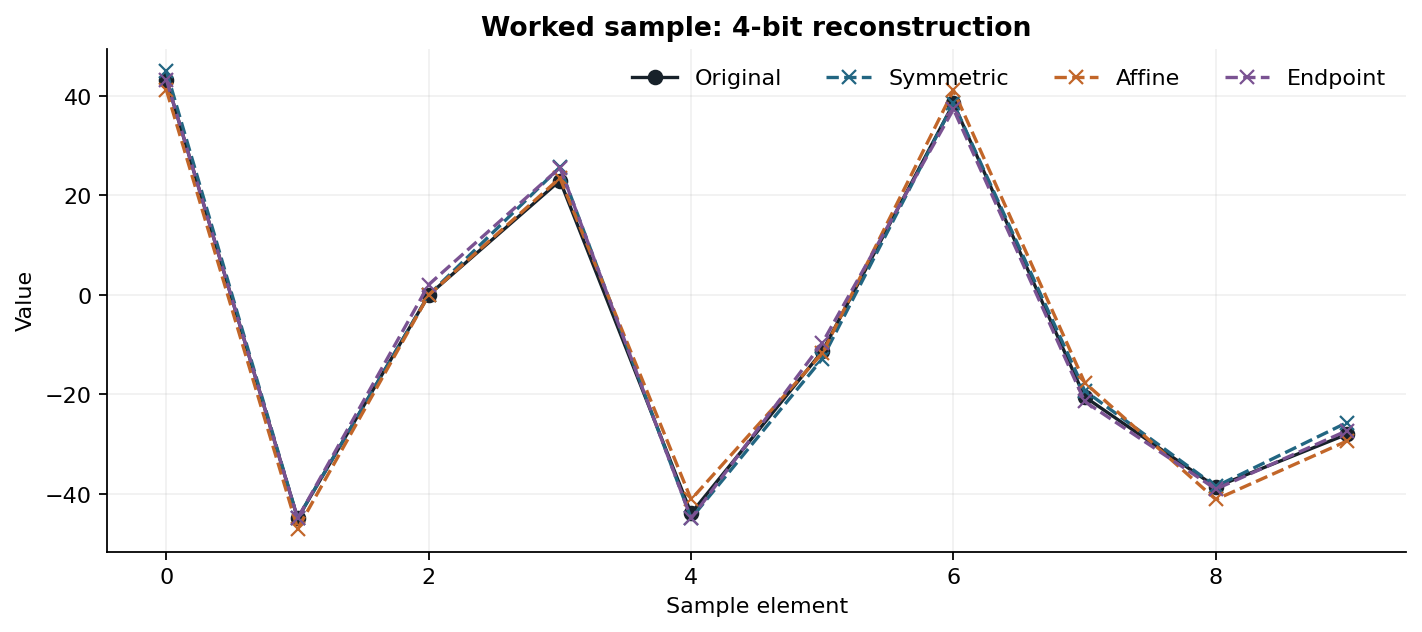

In [6]:
from software.quantization import SAMPLE, parameters, quantize, dequantize
sample_rows=[]
for method in ['symmetric','affine','endpoint']:
    p=parameters(SAMPLE,8,method)
    q=quantize(SAMPLE,p)
    print(method, '| scale =',p.scale,'| zero =',p.zero_point,'| codes =',q.tolist())
    sample_rows.append(pd.DataFrame({'original':SAMPLE,'code':q,'reconstructed':dequantize(q,p,np.float64),'method':method}))
display(pd.concat(sample_rows,ignore_index=True))
assert quantize(SAMPLE,parameters(SAMPLE,8,'affine'))[3]==197
figure('results/figures/worked_example.png')


In [7]:
answer_section(4)

## 4. Data and FP32 model training

Official Fashion-MNIST training data are split class-wise using seed 42: 54,000 train and 6,000 validation. The official 10,000-image test set remains separate. Exactly 1,000 calibration indices are sampled from the training indices using seed 101 and saved. No test labels select checkpoints, ranges, pruning rates or bit-widths.

Images are divided by 255 and zero-padded from 28×28 to 32×32. The concrete LeNet variant is defined below. C3 is fully connected across its input channels, pooling has no trainable parameters, and tanh follows both convolutions and pooling. It is a clearly specified dense LeNet variant rather than a claim to reproduce the original sparse C3 and trainable-subsampling network exactly.

| Layer | Output shape | Parameters | Dense MACs |
| --- | --- | --- | --- |
| Input | 1 × 32 × 32 | 0 | 0 |
| C1: Conv 5×5 + tanh | 6 × 28 × 28 | 156 | 117600 |
| S2: AvgPool 2×2 + tanh | 6 × 14 × 14 | 0 | 0 |
| C3: Conv 5×5 + tanh | 16 × 10 × 10 | 2416 | 240000 |
| S4: AvgPool 2×2 + tanh | 16 × 5 × 5 | 0 | 0 |
| C5: Conv 5×5 + tanh | 120 × 1 × 1 | 48120 | 48000 |
| F6: Linear + tanh | 84 | 10164 | 10080 |
| F7: Linear logits | 10 | 850 | 840 |
| Total | — | 61706 | 416520 |

For each convolution, the dense MAC count is Hout × Wout × Cout × Cin × Kh × Kw. Each linear layer uses Cin × Cout MACs. Bias additions, tanh, pooling and softmax are outside this MAC count. F7 returns raw logits for cross-entropy training. Softmax is only a presentation of class probabilities; it is not applied before the training loss. Prediction uses the largest logit, with the first class index selected on a tie.

AdamW uses batch size 256, learning rate 0.001, weight decay 0.0001 and learning-rate drops by 0.5 at epochs 10 and 16. Initialization seed is 7; shuffle seed is 42. All 20 epochs are completed and minimum validation cross-entropy selects epoch 20. The official-test result is **88.84%**. CPU execution uses 4 threads for training. Exact seeds, timing, versions, history, split indices and source hashes are saved.

![Training](results/figures/training.png)



Recomputed full-test FP32: {'n': 10000, 'correct': 8884, 'accuracy': 0.8884, 'cross_entropy': 0.3114386741638184}
Parameters: 61706 | Selected epoch: 20


,T-shirt/top,Trouser,Pullover,Dress,Coat,Sandal,Shirt,Sneaker,Bag,Ankle boot
True class; columns are predictions,,,,,,,,,,
T-shirt/top,864,0,20,25,2,1,78,0,10,0
Trouser,2,976,3,12,2,0,4,0,1,0
Pullover,18,2,828,12,68,0,70,0,2,0
Dress,13,9,12,921,20,1,20,0,4,0
Coat,0,1,123,48,757,0,69,0,2,0
Sandal,0,0,0,0,0,963,0,27,1,9
Shirt,140,2,88,32,60,0,669,0,9,0
Sneaker,0,0,0,0,0,9,0,973,0,18
Bag,5,0,3,7,1,2,1,5,976,0


,class,images,correct,accuracy_percent
0,T-shirt/top,1000,864,86.4
1,Trouser,1000,976,97.6
2,Pullover,1000,828,82.8
3,Dress,1000,921,92.1
4,Coat,1000,757,75.7
5,Sandal,1000,963,96.3
6,Shirt,1000,669,66.9
7,Sneaker,1000,973,97.3
8,Bag,1000,976,97.6
9,Ankle boot,1000,957,95.7


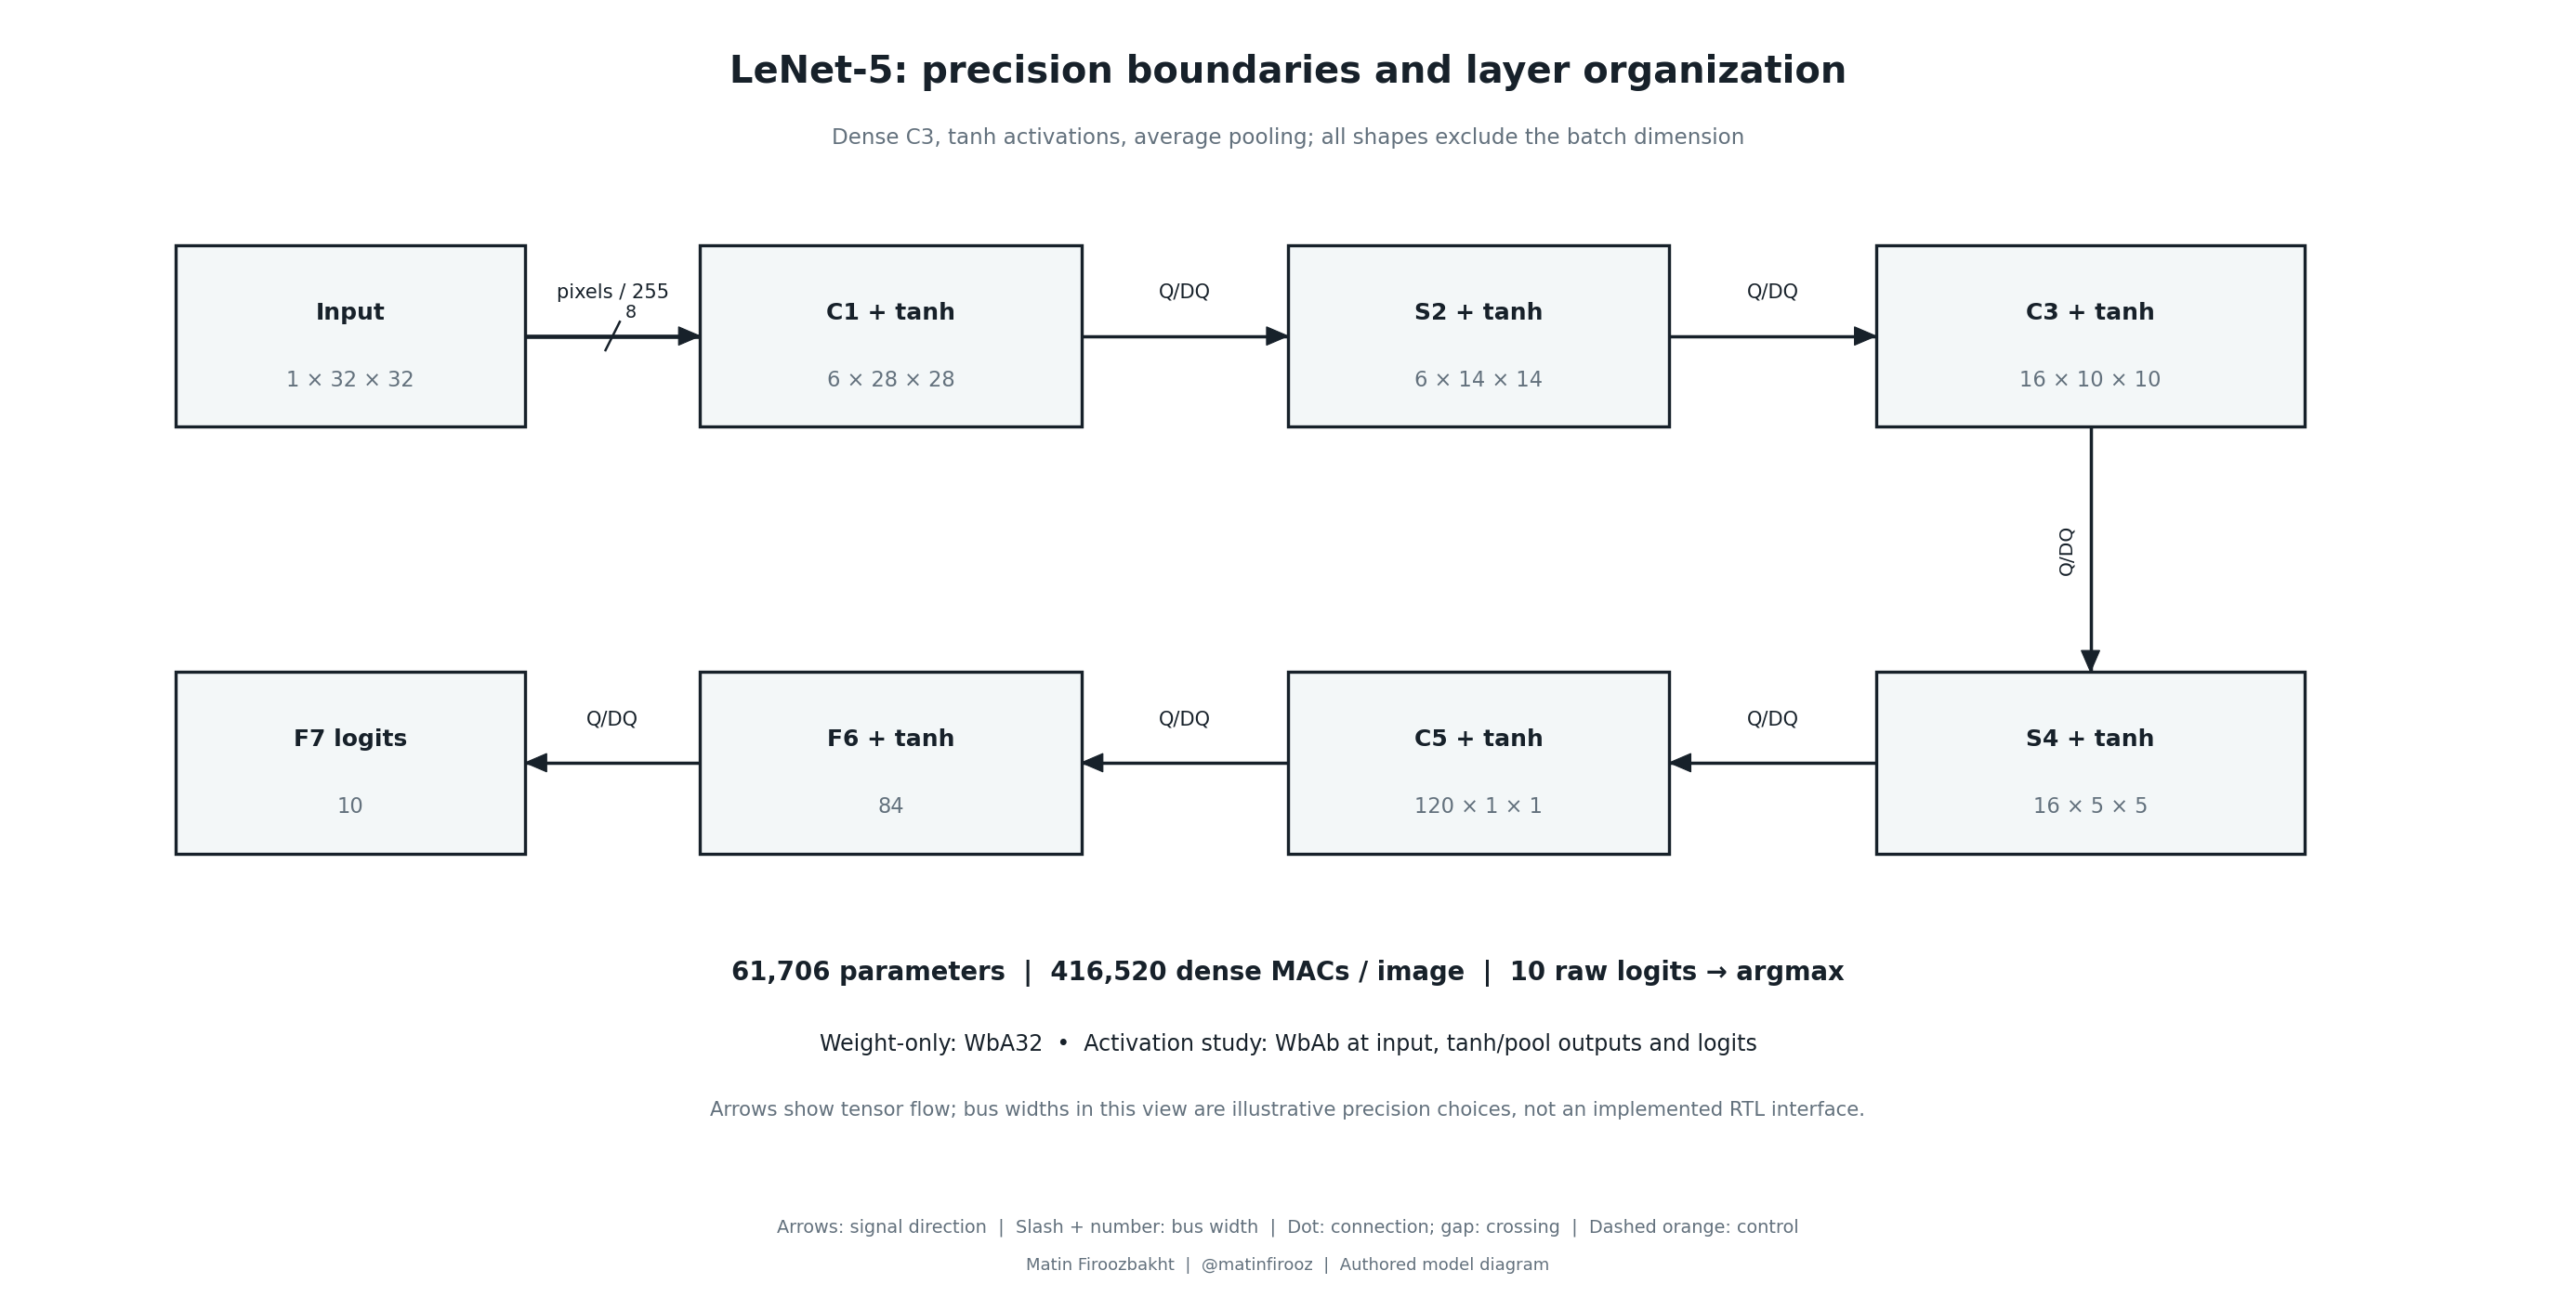

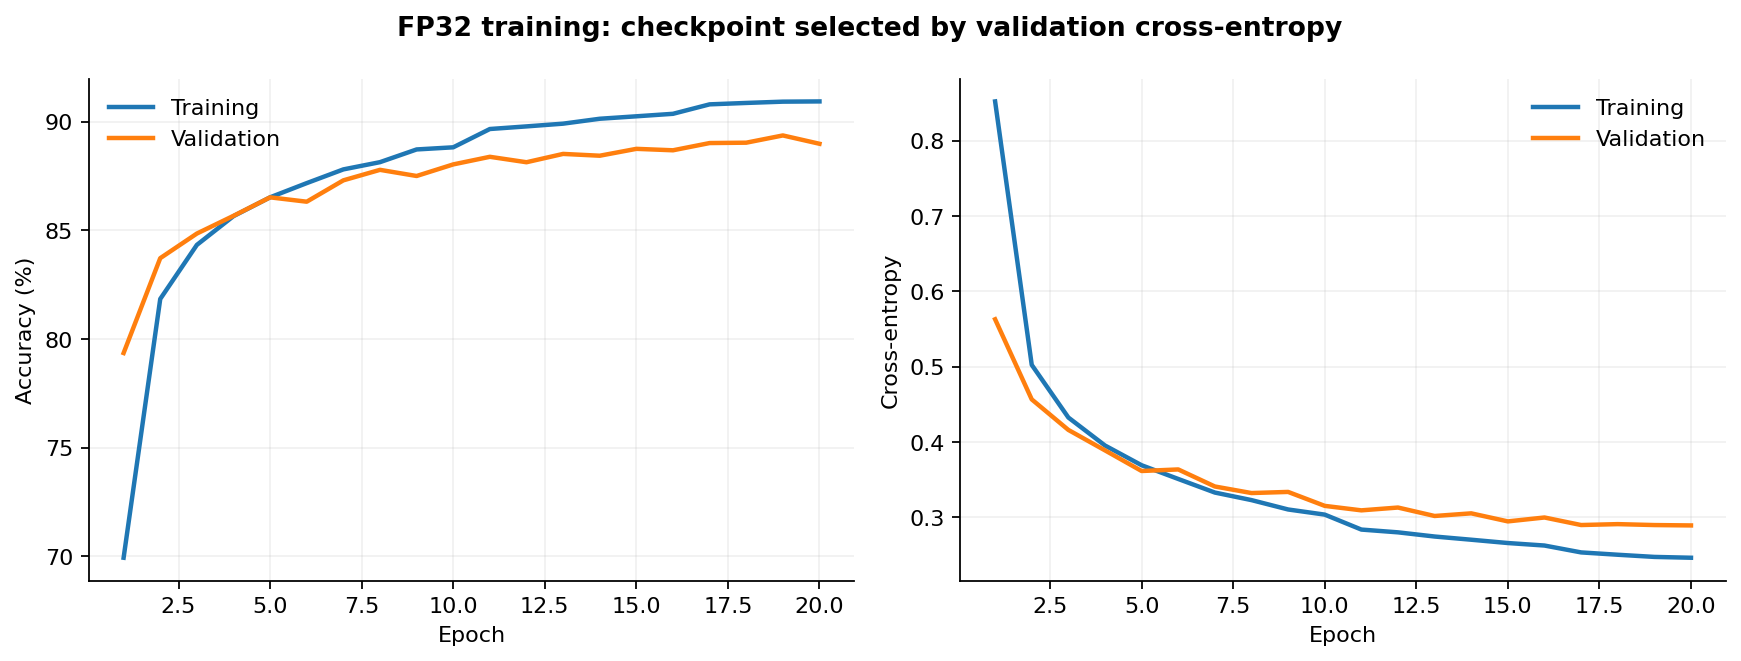

In [8]:
from software.data import load_idx, split_indices, CLASSES
from software.model import LeNet, prepare_pixels
from scripts.train import evaluate
raw, labels=load_idx(ROOT/'data/fashion','t10k')
checkpoint=torch.load(ROOT/'software/lenet_fashion_mnist.pt',map_location='cpu',weights_only=True)
model=LeNet().eval(); model.load_state_dict(checkpoint['state_dict'])
measured, logits=evaluate(model,prepare_pixels(raw),torch.tensor(labels,dtype=torch.long))
expected=json.loads((ROOT/'results/software/training_summary.json').read_text())['test']
assert measured['correct']==expected['correct']
print('Recomputed full-test FP32:', measured)
print('Parameters:',sum(p.numel() for p in model.parameters()),'| Selected epoch:',checkpoint['epoch'])
predictions=logits.argmax(1)
confusion=np.zeros((10,10),dtype=np.int32)
np.add.at(confusion,(labels,predictions),1)
display(pd.DataFrame(confusion,index=CLASSES,columns=CLASSES).rename_axis('True class; columns are predictions'))
display(pd.DataFrame({'class':CLASSES,'images':np.bincount(labels,minlength=10),'correct':np.diag(confusion),'accuracy_percent':np.diag(confusion)/np.bincount(labels,minlength=10)*100}))
figure('hardware/figures/lenet_architecture.png')
figure('results/figures/training.png')


In [9]:
answer_section(5)

## 5. Step 1: NumPy-only model evaluation

`software/quantization.py` implements the numerical grids without importing a neural-network framework. `software/numpy_lenet.py` implements im2col convolution, matrix multiplication, tanh, average pooling and stable cross-entropy using NumPy. `scripts/run_manual.py` is run in an isolated process and records that no PyTorch, TensorFlow, JAX or Keras module was imported.

For weight-only evaluation, all five weight tensors are quantized per tensor, then reconstructed, while biases and activations stay FP32. The WbAb extension also quantizes eight activation points using fixed training-calibration extrema: input, C1 tanh, S2 tanh, C3 tanh, S4 tanh, C5 tanh, F6 tanh and logits. Arithmetic and nonlinear functions are FP32 in both modes.

The NumPy FP32 implementation agrees with every one of the 10,000 PyTorch baseline predictions. Maximum logit discrepancy is 6.6757202e-06, consistent with different floating-point reduction orders. These are numerical equivalence results, not integer-kernel timing results.

| Bits | Method | WbA32 correct / 10,000 | WbA32 accuracy (%) | WbAb accuracy (%) |
| --- | --- | --- | --- | --- |
| 16 | symmetric | 8884 | 88.84 | 88.84 |
| 16 | affine | 8884 | 88.84 | 88.84 |
| 16 | endpoint | 8884 | 88.84 | 88.84 |
| 8 | symmetric | 8885 | 88.85 | 88.82 |
| 8 | affine | 8884 | 88.84 | 88.85 |
| 8 | endpoint | 8887 | 88.87 | 88.78 |
| 4 | symmetric | 8826 | 88.26 | 86.26 |
| 4 | affine | 8820 | 88.20 | 86.80 |
| 4 | endpoint | 8750 | 87.50 | 85.14 |

![Manual evaluation](results/figures/manual_accuracy.png)



Independent NumPy process: {'n': 10000, 'correct': 8884, 'accuracy': 0.8884, 'cross_entropy': 0.3114386796951294, 'torch_max_logit_error': 6.67572021484375e-06, 'torch_prediction_disagreements': 0}
Neural-network package imports: []
Fresh NumPy-only import probe passed.


,method,bits,mode,n,correct,accuracy,cross_entropy
0,symmetric,16,weights_only,10000,8884,0.8884,0.311437
1,symmetric,16,weights_activations,10000,8884,0.8884,0.311438
2,affine,16,weights_only,10000,8884,0.8884,0.311439
3,affine,16,weights_activations,10000,8884,0.8884,0.311438
4,endpoint,16,weights_only,10000,8884,0.8884,0.311438
5,endpoint,16,weights_activations,10000,8884,0.8884,0.311438
6,symmetric,8,weights_only,10000,8885,0.8885,0.310673
7,symmetric,8,weights_activations,10000,8882,0.8882,0.310920
8,affine,8,weights_only,10000,8884,0.8884,0.311381
9,affine,8,weights_activations,10000,8885,0.8885,0.311533


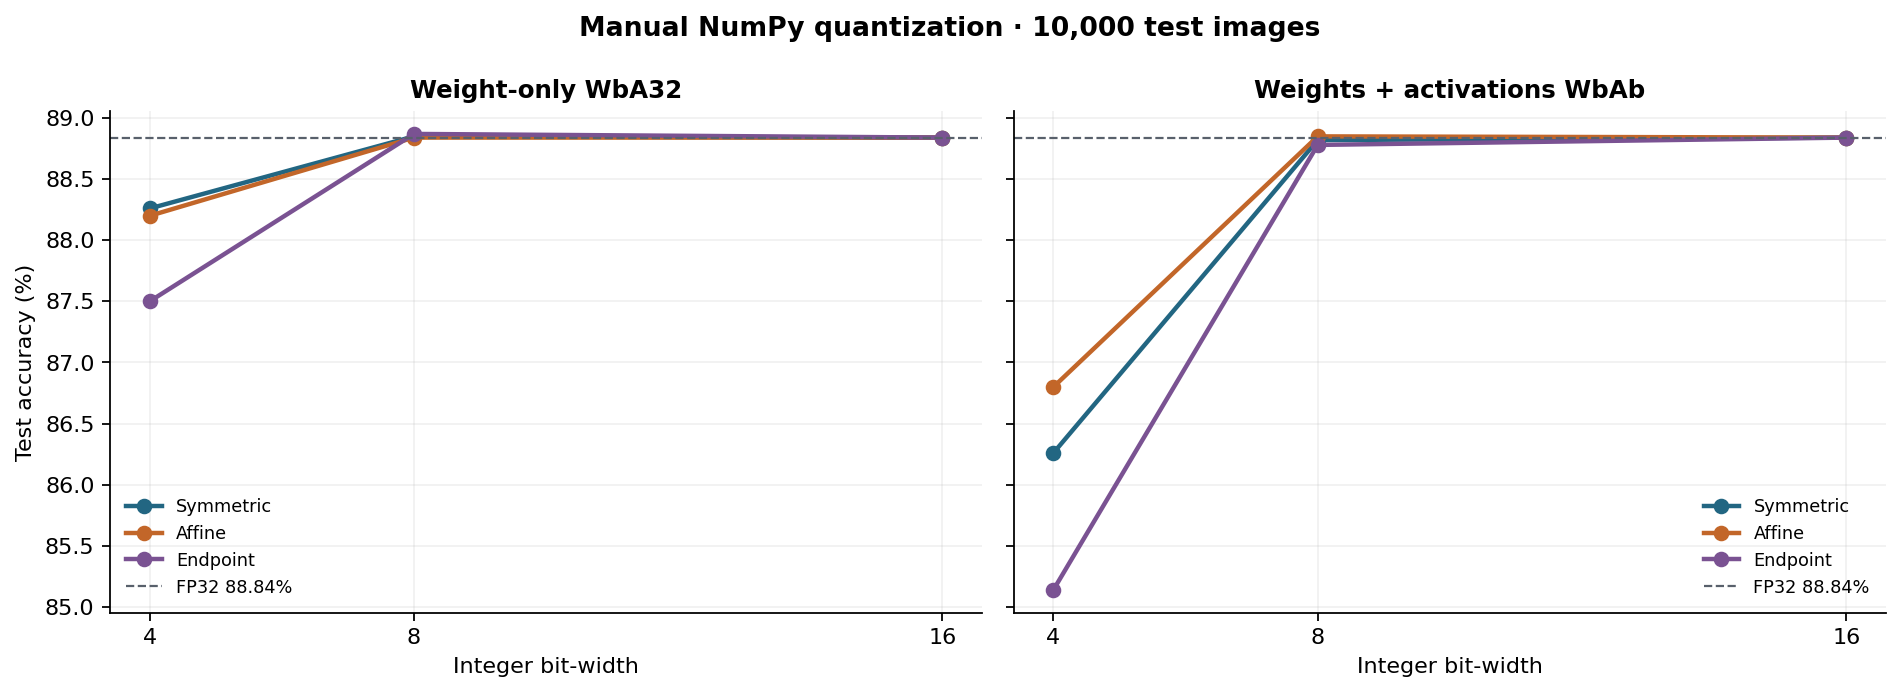

In [10]:
manual=json.loads((ROOT/'results/quantization/manual_results.json').read_text())
assert manual['neural_network_imports']==[]
assert manual['baseline']['torch_prediction_disagreements']==0
print('Independent NumPy process:',manual['baseline'])
print('Neural-network package imports:',manual['neural_network_imports'])
probe=subprocess.run([sys.executable,'-c',"import sys; from software.numpy_lenet import forward; assert not any(n in sys.modules for n in ['torch','tensorflow','jax','keras']); print('Fresh NumPy-only import probe passed.')"],capture_output=True,text=True,cwd=ROOT,check=True)
print(probe.stdout.strip())
display(pd.DataFrame(manual['results']))
figure('results/figures/manual_accuracy.png')


In [11]:
answer_section(6)

## 6. Step 2: PyTorch PTQ and precision coverage

Train FP32 once, then quantize without changing its learned parameters through optimization. The assignment defines PTQ as post-training conversion; its later wording about training at each precision is interpreted as preparing and evaluating each quantized model from the trained baseline. Quantization-aware training is a different method and is not silently substituted for PTQ. The pruning recovery experiments are explicitly separate.

FP16 evaluates an actual half-precision model and half-precision inputs on the CPU. For INT16/8/4/2, PyTorch 2.5.1 `FakeQuantize` and `MinMaxObserver` compute per-tensor grid parameters. Custom ranges are carried by qint8/quint8 for up to eight logical bits and qint32 for the 16-bit grid. The storage carrier does not imply an INT16 convolution kernel. Weight observers see the trained weights. Activation observers see frozen FP32 extrema measured on the 1,000 training calibration images; observers are disabled for evaluation.

Weights are reconstructed on the selected grid and retained in a saved FP32 Q/DQ state dictionary. Activation quantization uses `torch.fake_quantize_per_tensor_affine`. Codes for export are recovered from the actual PyTorch fake-quantized output, then reconstructed and compared exactly. This avoids assuming that float32 reciprocal multiplication at rounding boundaries is always identical to NumPy float64 division.

| Precision | Method | WbA32 correct | WbA32 accuracy (%) | WbAb accuracy (%) | WbA32 payload (bytes) | Compression |
| --- | --- | --- | --- | --- | --- | --- |
| FP32 | floating point | 8884 | 88.84 | — | 246824 | 1.00× |
| FP16 | floating point | 8885 | 88.85 | — | 123412 | 2.00× |
| INT16 | symmetric | 8884 | 88.84 | 88.84 | 123984 | 1.99× |
| INT16 | affine | 8884 | 88.84 | 88.84 | 123984 | 1.99× |
| INT8 | symmetric | 8885 | 88.85 | 88.82 | 62514 | 3.95× |
| INT8 | affine | 8884 | 88.84 | 88.85 | 62514 | 3.95× |
| INT4 | symmetric | 8826 | 88.26 | 86.26 | 31779 | 7.77× |
| INT4 | affine | 8820 | 88.20 | 86.80 | 31779 | 7.77× |
| INT2 | symmetric | 771 | 7.71 | 10.00 | 16412 | 15.04× |
| INT2 | affine | 2822 | 28.22 | 17.08 | 16412 | 15.04× |

A real converted INT8 model uses QuantStub/DeQuantStub, min–max activation observers with 0..255 codes, per-output-channel symmetric weight observers and the x86 quantized engine. All three Conv2d and both Linear modules are verified as quantized operators. It scores **88.29%** (8829/10,000). Tanh and pooling follow the quantized backend rules. Its grids differ from the controlled per-tensor Q/DQ experiment, so its accuracy difference is not a pure test of integer arithmetic alone. Native INT16, INT4 and INT2 speedups are not asserted.

![Framework evaluation](results/figures/pytorch_accuracy.png)



,name,method,bits,mode,execution,payload_bytes,compression_ratio,n,correct,accuracy,cross_entropy
0,FP32,float,32,floating_point,native FP32,246824,1.000000,10000,8884,0.8884,0.311439
1,FP16,float,16,floating_point,native FP16 CPU,123412,2.000000,10000,8885,0.8885,0.311319
2,INT16,symmetric,16,weights_only,FP32 Q/DQ simulation,123984,1.990773,10000,8884,0.8884,0.311437
3,INT16,symmetric,16,weights_activations,FP32 Q/DQ simulation,124144,1.988207,10000,8884,0.8884,0.311438
4,INT16,affine,16,weights_only,FP32 Q/DQ simulation,123984,1.990773,10000,8884,0.8884,0.311439
5,INT16,affine,16,weights_activations,FP32 Q/DQ simulation,124144,1.988207,10000,8884,0.8884,0.311438
6,INT8,symmetric,8,weights_only,FP32 Q/DQ simulation,62514,3.948300,10000,8885,0.8885,0.310673
7,INT8,symmetric,8,weights_activations,FP32 Q/DQ simulation,62674,3.938220,10000,8882,0.8882,0.310920
8,INT8,affine,8,weights_only,FP32 Q/DQ simulation,62514,3.948300,10000,8884,0.8884,0.311381
9,INT8,affine,8,weights_activations,FP32 Q/DQ simulation,62674,3.938220,10000,8885,0.8885,0.311509


,name,method,bits,mode,execution,checkpoint_bytes,n,correct,accuracy,cross_entropy
0,Native INT8,per_channel_weight_affine_activation,8,weights_activations,quantized CPU operators,75846,10000,8829,0.8829,0.320299


,layer,operator,weight_dtype,qscheme,shape
0,net.conv1,torch.ao.nn.quantized.modules.conv.Conv2d,torch.qint8,torch.per_channel_affine,"[6, 1, 5, 5]"
1,net.conv3,torch.ao.nn.quantized.modules.conv.Conv2d,torch.qint8,torch.per_channel_affine,"[16, 6, 5, 5]"
2,net.conv5,torch.ao.nn.quantized.modules.conv.Conv2d,torch.qint8,torch.per_channel_affine,"[120, 16, 5, 5]"
3,net.fc6,torch.ao.nn.quantized.modules.linear.Linear,torch.qint8,torch.per_channel_affine,"[84, 120]"
4,net.fc7,torch.ao.nn.quantized.modules.linear.Linear,torch.qint8,torch.per_channel_affine,"[10, 84]"


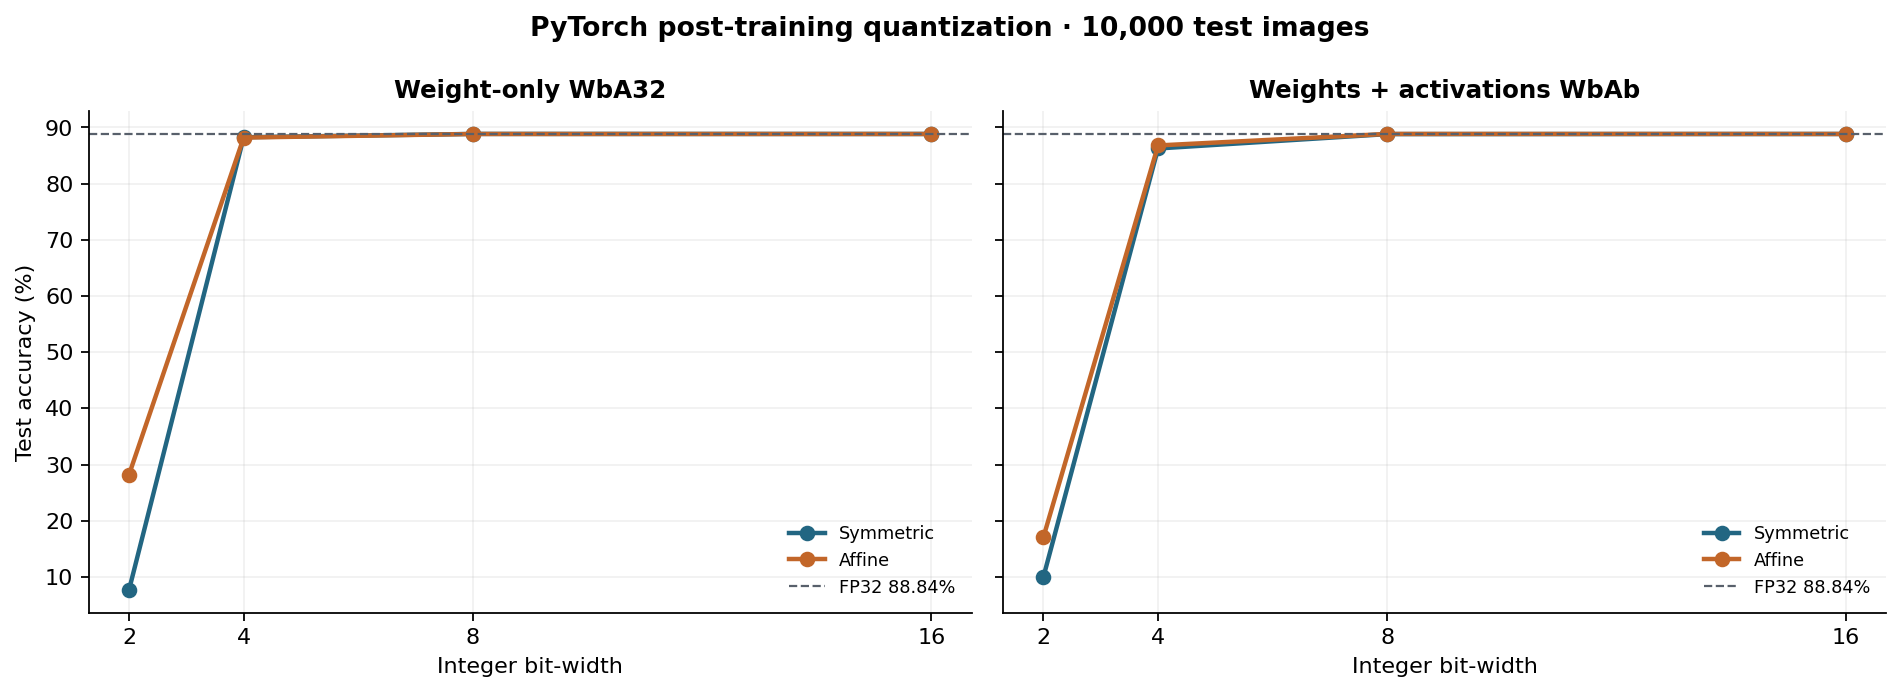

In [12]:
framework=json.loads((ROOT/'results/quantization/pytorch_results.json').read_text())
display(pd.DataFrame(framework['results']))
display(pd.DataFrame([framework['native_int8']]))
display(pd.DataFrame(framework['native_operators']))
figure('results/figures/pytorch_accuracy.png')


In [13]:
answer_section(7)

## 7. Answers to the analysis questions

**How does quantization affect accuracy?** FP32 scores 88.84% and FP16 88.85%. At sixteen bits, symmetric and affine weight-only accuracy are 88.84% and 88.84%. At eight bits they are 88.85% and 88.84%, with W8A8 at 88.82% and 88.85%. At two bits, the weight-only results are 7.71% symmetric and 28.22% affine. Small differences on a single test set do not establish a repeatable accuracy improvement.

**What is the compression/accuracy trade-off?** FP32 parameter storage is 246,824 bytes. Packed weight-only payloads at INT16/8/4/2 are 123,984, 62,514, 31,779, 16,412 bytes. Their compression ratios are 1.99×, 3.95×, 7.77×, 15.04×, including biases and weight grid records. Four-bit symmetric weight-only inference scores 88.26% with 7.77× compression. WbAb additionally stores activation grid records; its complete byte counts are included in the result files. JSON, serialization overhead and activation working buffers are separate quantities.

**Which method works better?** Compare each policy separately. At four bits, symmetric weight-only accuracy is 88.26% and affine is 88.20%. W4A4 scores 86.26% symmetric and 86.80% affine. The literal endpoint grid scores 87.50% weight-only and 85.14% W4A4. Outliers, per-tensor range selection and activation rounding affect these outcomes. The native per-channel configuration is reported independently.

**At what bit-width does accuracy significantly degrade?** Use a descriptive threshold of a one-percentage-point loss from FP32. At four bits, symmetric and affine weight-only losses are 0.58 and 0.64 points. The corresponding W4A4 losses are 2.58 and 2.04 points. The first width crossing this threshold when stepping through 16, 8, 4 and 2 bits is: symmetric weights_only: 2; symmetric weights_activations: 4; affine weights_only: 2; affine weights_activations: 4. This is an explanatory convention, not a hypothesis test or a bit-width selected to optimize test accuracy.

**Can reduced memory be claimed as a speedup?** Q/DQ uses FP32 operators. Native low-precision kernels and sparse formats also have dispatch, packing and indexing costs. The separate CPU measurements describe the tested host and shapes; parameter compression alone is not a latency measurement.


![Storage trade-off](results/figures/compression_accuracy.png)



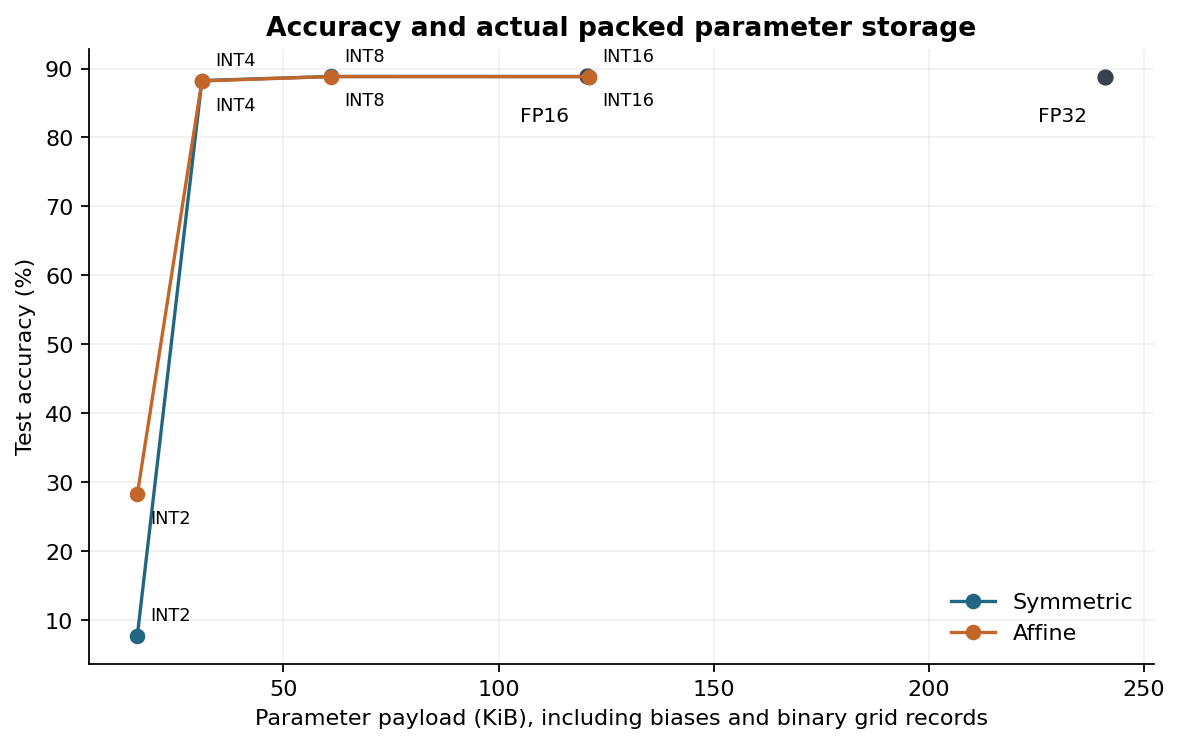

In [14]:
figure('results/figures/compression_accuracy.png')

In [15]:
answer_section(8)

## 8. Pruning extension

The source title and introduction mention pruning but prescribe no pruning algorithm or rates. This additional study fixes global L1 weight sparsities of 0%, 25%, 50%, 75% and 90%, preserving biases. PyTorch masks remain attached during recovery, so masked connections cannot regrow. Mask removal occurs only after recovery when producing a normal state dictionary. Due to rounding of the requested number of weights, 25% means 15,368 of 61,470 weights and 75% means 46,102 weights; exact measured sparsities are saved.

| Pruning | Correct / 10,000 | Accuracy (%) | CSR payload (bytes) | Dense MACs / image |
| --- | --- | --- | --- | --- |
| 0% global L1 | 8884 | 88.84 | 370728 | 416520 |
| 25% global L1 | 8887 | 88.87 | 278520 | 416520 |
| 50% global L1 | 8795 | 87.95 | 186318 | 416520 |
| 75% global L1 | 8252 | 82.52 | 94116 | 416520 |
| 90% global L1 | 4195 | 41.95 | 38790 | 416520 |
| 75% + 3 recovery epochs | 8799 | 87.99 | 94116 | 416520 |
| Compacted + 3 recovery epochs | 8787 | 87.87 | 139,116 dense FP32 | 231700 |

The recovered 75% sparse model reaches 87.99%; the joint recovered-sparse plus weight-only symmetric INT8 model reaches 88.01%. Recovery uses three AdamW epochs at learning rate 0.0001 with fixed seed 17 and validation cross-entropy checkpoint selection.

A second experiment physically compacts channels from 6/16/120/84 to 4/12/90/63. L1 output-row scores select channels from the trained dense weights, and the kept indices are propagated through subsequent inputs, including both dense layers. Before recovery the compact model is 73.30%; after three recovery epochs it is 87.87%. The compact tensors have 34,779 parameters and 231,700 dense MACs per image, reductions of 43.64% and 44.37%. Before recovery its outputs match a corresponding masked full-sized network within 1.4305115e-06 maximum logit error.

Sparse export uses FP32 values (4 bytes), uint16 column indices (2 bytes), uint32 row pointers and FP32 biases. For the full network there are 236 output rows across the five learned layers and five extra terminal row-pointer entries, hence 964 row-pointer bytes. Total CSR payload is **6 × nnz + 964 + 944 bytes**. Below sufficient sparsity, indices can make storage larger than dense FP32, as the 25% result demonstrates. Zero masks alone retain dense tensor dimensions and dense MAC counts. Channel compaction provides a direct reduction in those dimensions.

![Pruning](results/figures/pruning.png)



Recovered 75% sparse: 8799 / 10000
Compacted: 34779 parameters, 231700 dense MACs/image
Compaction masked-reference maximum error: 1.430511474609375e-06


,rate,kind,parameters,weight_count,zero_weights,weight_sparsity,n,correct,accuracy,cross_entropy,sparse_payload_bytes,sparse_compression_ratio,dense_macs
0,0.00,"global magnitude, no recovery",61706,61470,0,0.000000,10000,8884,0.8884,0.311439,370728,0.665782,416520
1,0.25,"global magnitude, no recovery",61706,61470,15368,0.250008,10000,8887,0.8887,0.310647,278520,0.886198,416520
2,0.50,"global magnitude, no recovery",61706,61470,30735,0.500000,10000,8795,0.8795,0.334371,186318,1.324746,416520
3,0.75,"global magnitude, no recovery",61706,61470,46102,0.749992,10000,8252,0.8252,0.477759,94116,2.622551,416520
4,0.90,"global magnitude, no recovery",61706,61470,55323,0.900000,10000,4195,0.4195,1.680267,38790,6.363083,416520


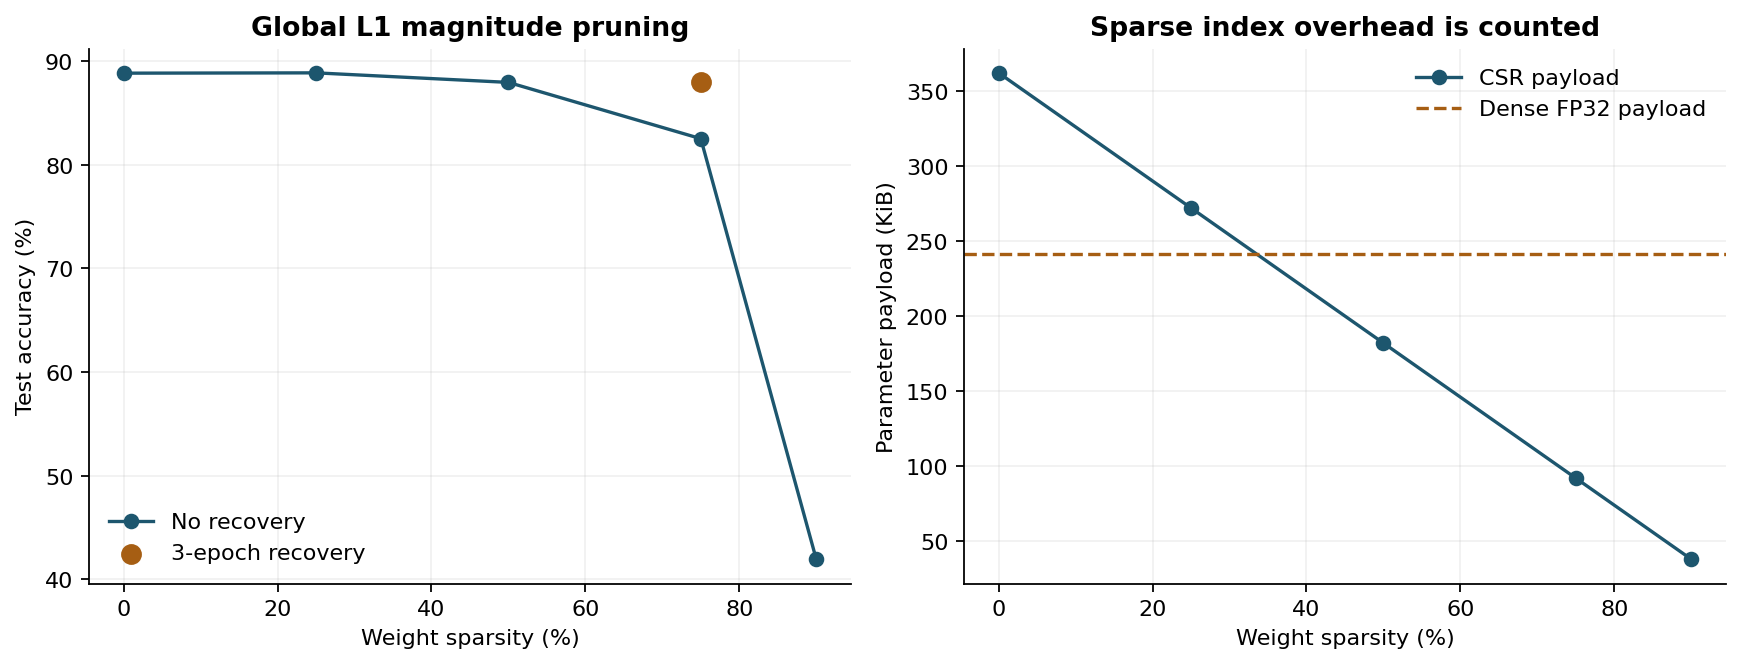

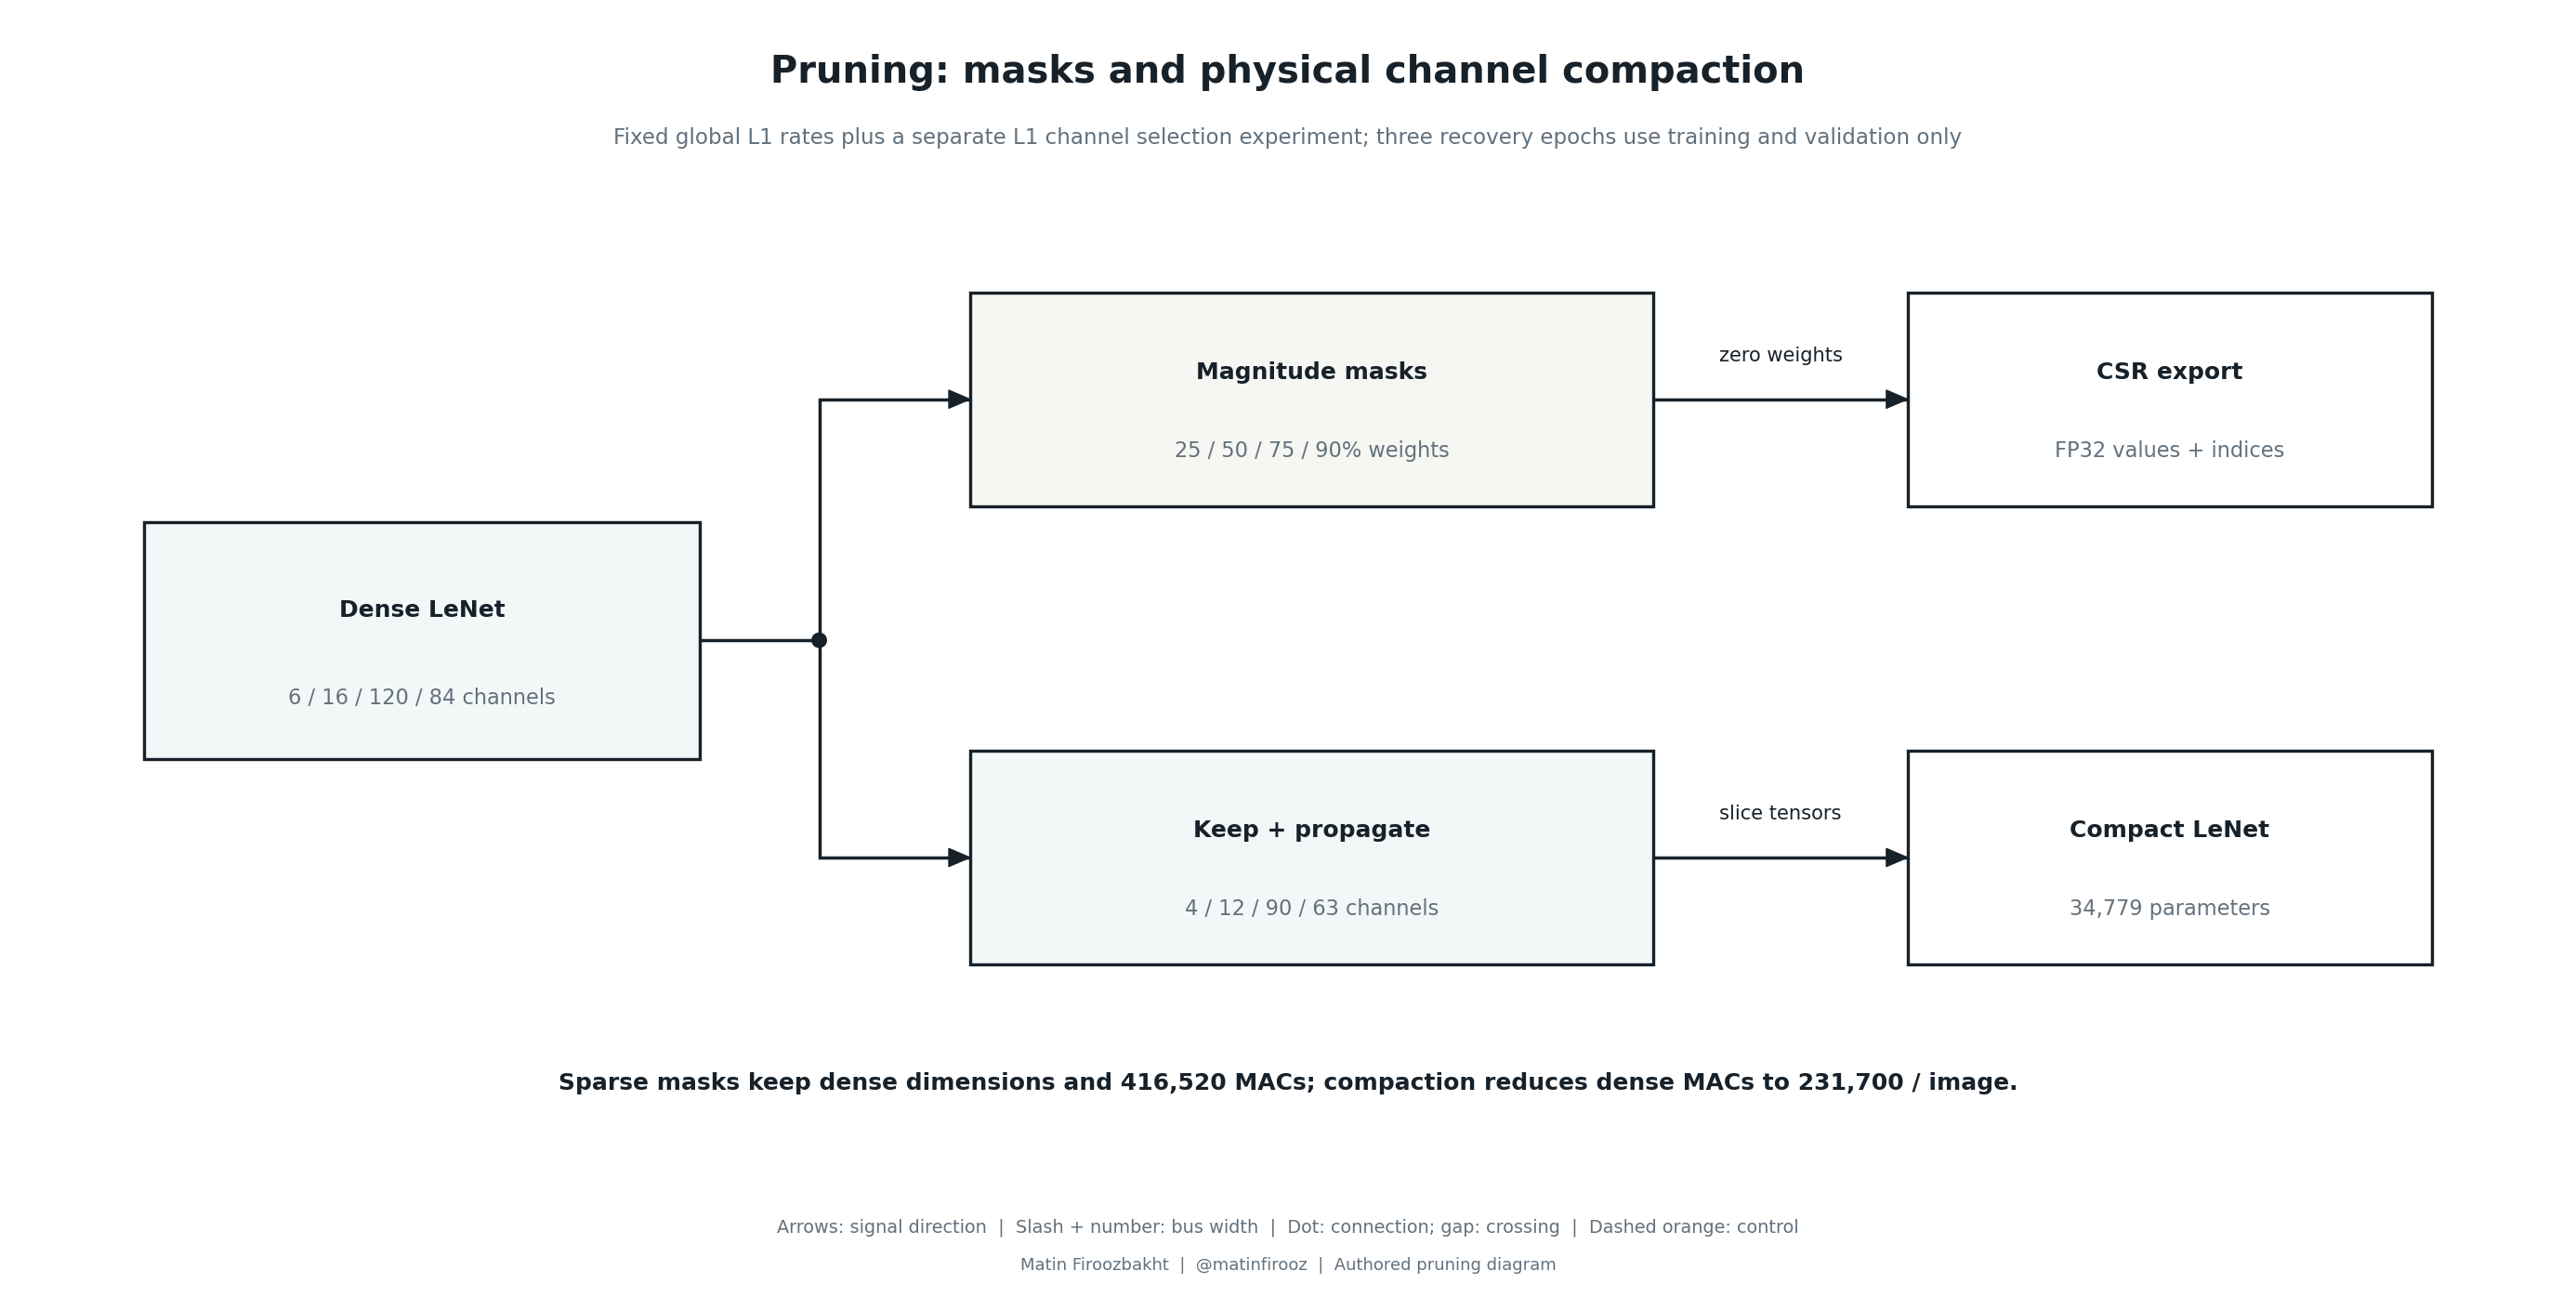

In [16]:
pruning=json.loads((ROOT/'results/pruning/pruning_results.json').read_text())
display(pd.DataFrame(pruning['rates']))
print('Recovered 75% sparse:',pruning['recovered']['correct'],'/ 10000')
print('Compacted:',pruning['compact']['parameters'],'parameters,',pruning['compact']['dense_macs'],'dense MACs/image')
print('Compaction masked-reference maximum error:',pruning['compact']['masked_equivalence_max_error'])
figure('results/figures/pruning.png')
figure('hardware/figures/pruning_compaction.png')


In [17]:
answer_section(9)

## 9. Hardware preparation and numerical contract

Convolutions use OIHW and linear layers OI layout, both flattened in C order. INT2/4/8/16 packing uses the first code in the least significant bits of the byte; signed values are two’s-complement and 16-bit words are little-endian. Each layer starts on a byte boundary. All padding bits are zero. Metadata gives shapes, counts, byte offsets, scales, zero-points and SHA-256.

For integer affine operands, the exact widened accumulation is:

$$A_j=\sum_{i=0}^{K-1}(q_{x,i}-z_x)(q_{w,ji}-z_w)+b_{q,j},$$
$$b_{q,j}=\operatorname{round}(b_j/(s_xs_w)),\qquad \hat{y}_j=s_xs_w A_j.$$

Equivalent correction before adding bias is:

$$\sum_i q_{x,i}q_{w,ji}-z_w\sum_i q_{x,i}-z_x\sum_i q_{w,ji}+Kz_xz_w.$$

The exporter supplies optional INT64 bias codes, per-layer conservative accumulator bounds, required signed widths and an exact central C1 patch golden vector. The first image's padded input patch at row/column 12 is used, providing nontrivial pixel values. W16 products/accumulations can exceed 32 bits, so the reference widens before subtraction and multiplication. Zero-point subtraction can require b+1 signed bits for an unsigned b-bit code.

The evaluated Q/DQ paths retain FP32 biases; the rounded integer bias references are not substituted into those evaluations. A complete integer-only accelerator would additionally need a defined tanh approximation, average-pooling rounding, requantization policy, buffering, interface protocols and cycle-level verification. The supplied hardware diagrams are authored mapping references, and no complete RTL, synthesis or routed PPA is claimed.

`hardware/README.md` specifies each binary file and shows a decoder. Every packed weight export is round-trip checked against the saved evaluated model, and the integer dot-product identity is tested independently. Native per-channel INT8 exports retain their own scales and zero-points rather than reusing the per-tensor grid metadata.



### 9.1 Executable packed-weight runtime

`software/packed_runtime.py` and `scripts/infer_packed.py` load the binary weight/bias/grid files. Weight SHA-256, byte counts, shapes, offsets, grid descriptions, signed ranges and padding bits are checked. Activation grids are read from `activation_qparams.bin` when WbAb is selected. No trained PT/NPZ checkpoint or neural-network framework is needed by this runtime.

```bash
python scripts/infer_packed.py --method affine --bits 8 --index 0
python scripts/infer_packed.py --method symmetric --bits 4 --mode weights_activations --all
```

`python scripts/qualify_packed.py` reproduces all sixteen full-test evaluations below. Differences are counted against the corresponding saved PyTorch model predictions rather than assumed to be zero. Arithmetic after decoding is NumPy FP32 Q/DQ; integer code packing does not turn this execution into native integer convolution.

| Bits | Method | Policy | Accuracy (%) | Prediction differences vs PyTorch |
| --- | --- | --- | --- | --- |
| 16 | symmetric | weights_only | 88.84 | 0 |
| 16 | symmetric | weights_activations | 88.84 | 0 |
| 16 | affine | weights_only | 88.84 | 0 |
| 16 | affine | weights_activations | 88.84 | 0 |
| 8 | symmetric | weights_only | 88.85 | 0 |
| 8 | symmetric | weights_activations | 88.82 | 0 |
| 8 | affine | weights_only | 88.84 | 0 |
| 8 | affine | weights_activations | 88.85 | 0 |
| 4 | symmetric | weights_only | 88.26 | 0 |
| 4 | symmetric | weights_activations | 86.26 | 0 |
| 4 | affine | weights_only | 88.20 | 0 |
| 4 | affine | weights_activations | 86.80 | 0 |
| 2 | symmetric | weights_only | 7.71 | 0 |
| 2 | symmetric | weights_activations | 10.00 | 0 |
| 2 | affine | weights_only | 28.22 | 0 |
| 2 | affine | weights_activations | 17.08 | 0 |



All five layers and biases reconstructed exactly from packed bytes.
Central 5x5 input codes: [[  0   0   0   4   0]
 [  0   0   2   0  11]
 [  0   3   0   0 115]
 [  3   0   0  89 139]
 [  0   0  98 136 110]]
Exact centered INT64 MAC outputs: [[5211, -22750, -18862, 14461, 19772, 18123]]
Scaled preactivations: [[0.09720719121589143, -0.42438372676291114, -0.35185608150338593, 0.2697588163832289, 0.3688314305739024, 0.3380706057197468]]


,layer,shape,count,weight_byte_offset,weight_bytes,required_signed_accumulator_bits
0,conv1,"[6, 1, 5, 5]",150,0,150,21
1,conv3,"[16, 6, 5, 5]",2400,150,2400,23
2,conv5,"[120, 16, 5, 5]",48000,2550,48000,24
3,fc6,"[84, 120]",10080,50550,10080,23
4,fc7,"[10, 84]",840,60630,840,22


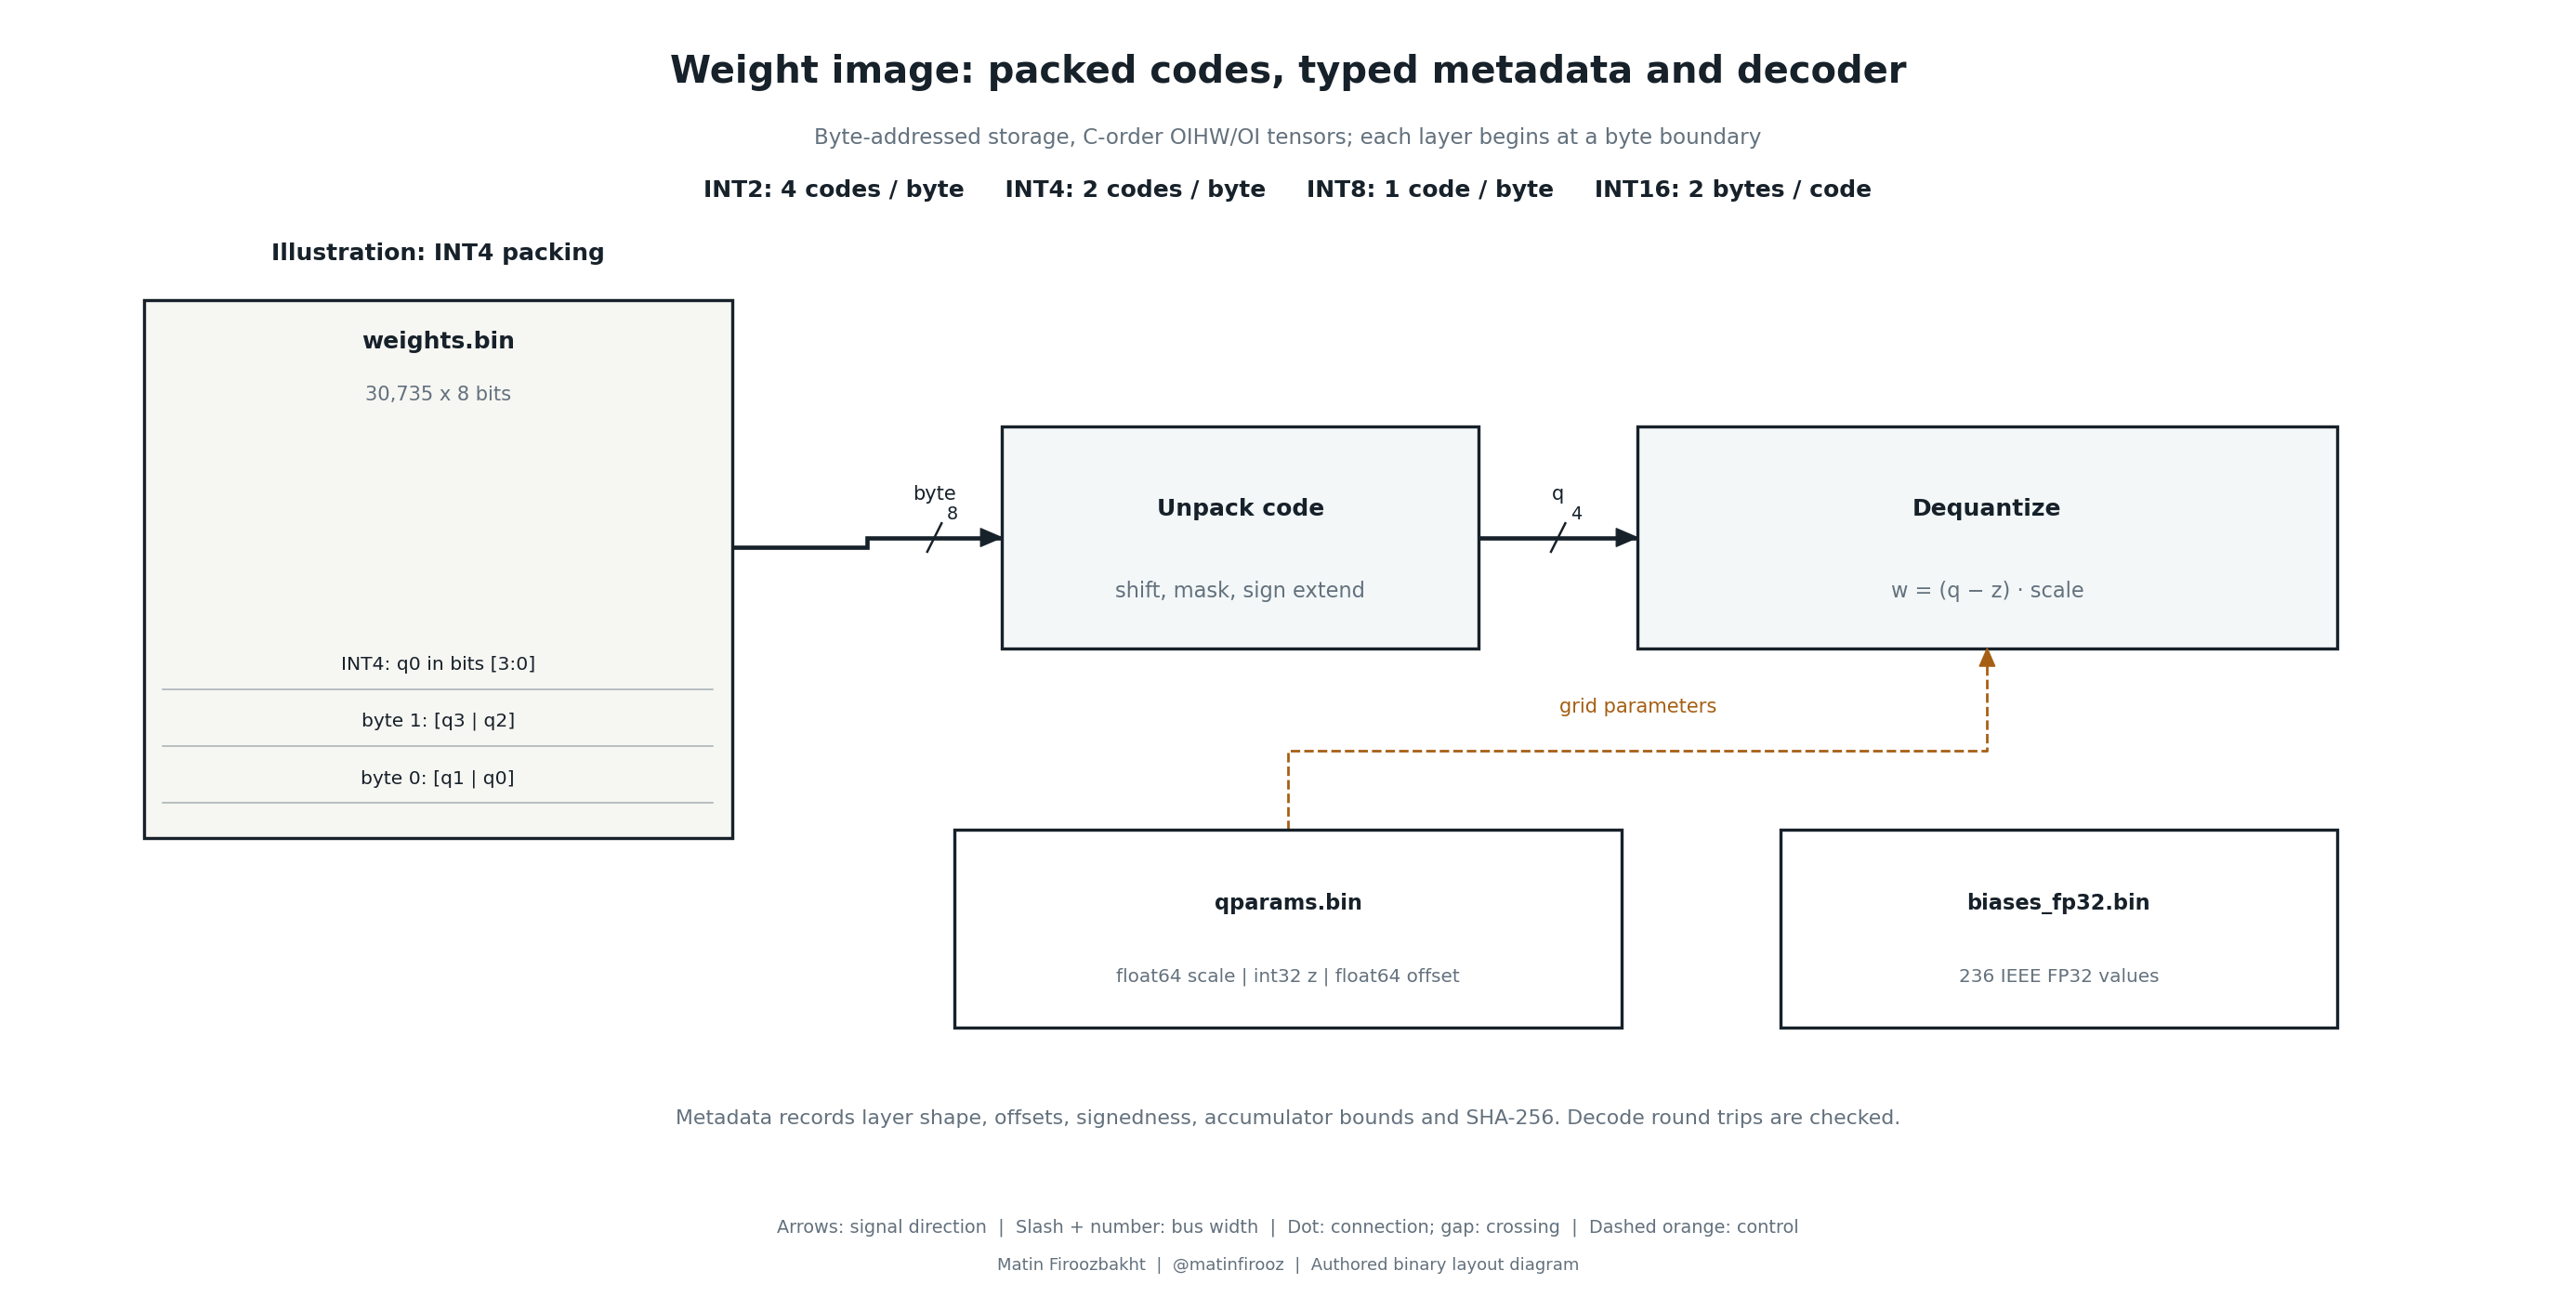

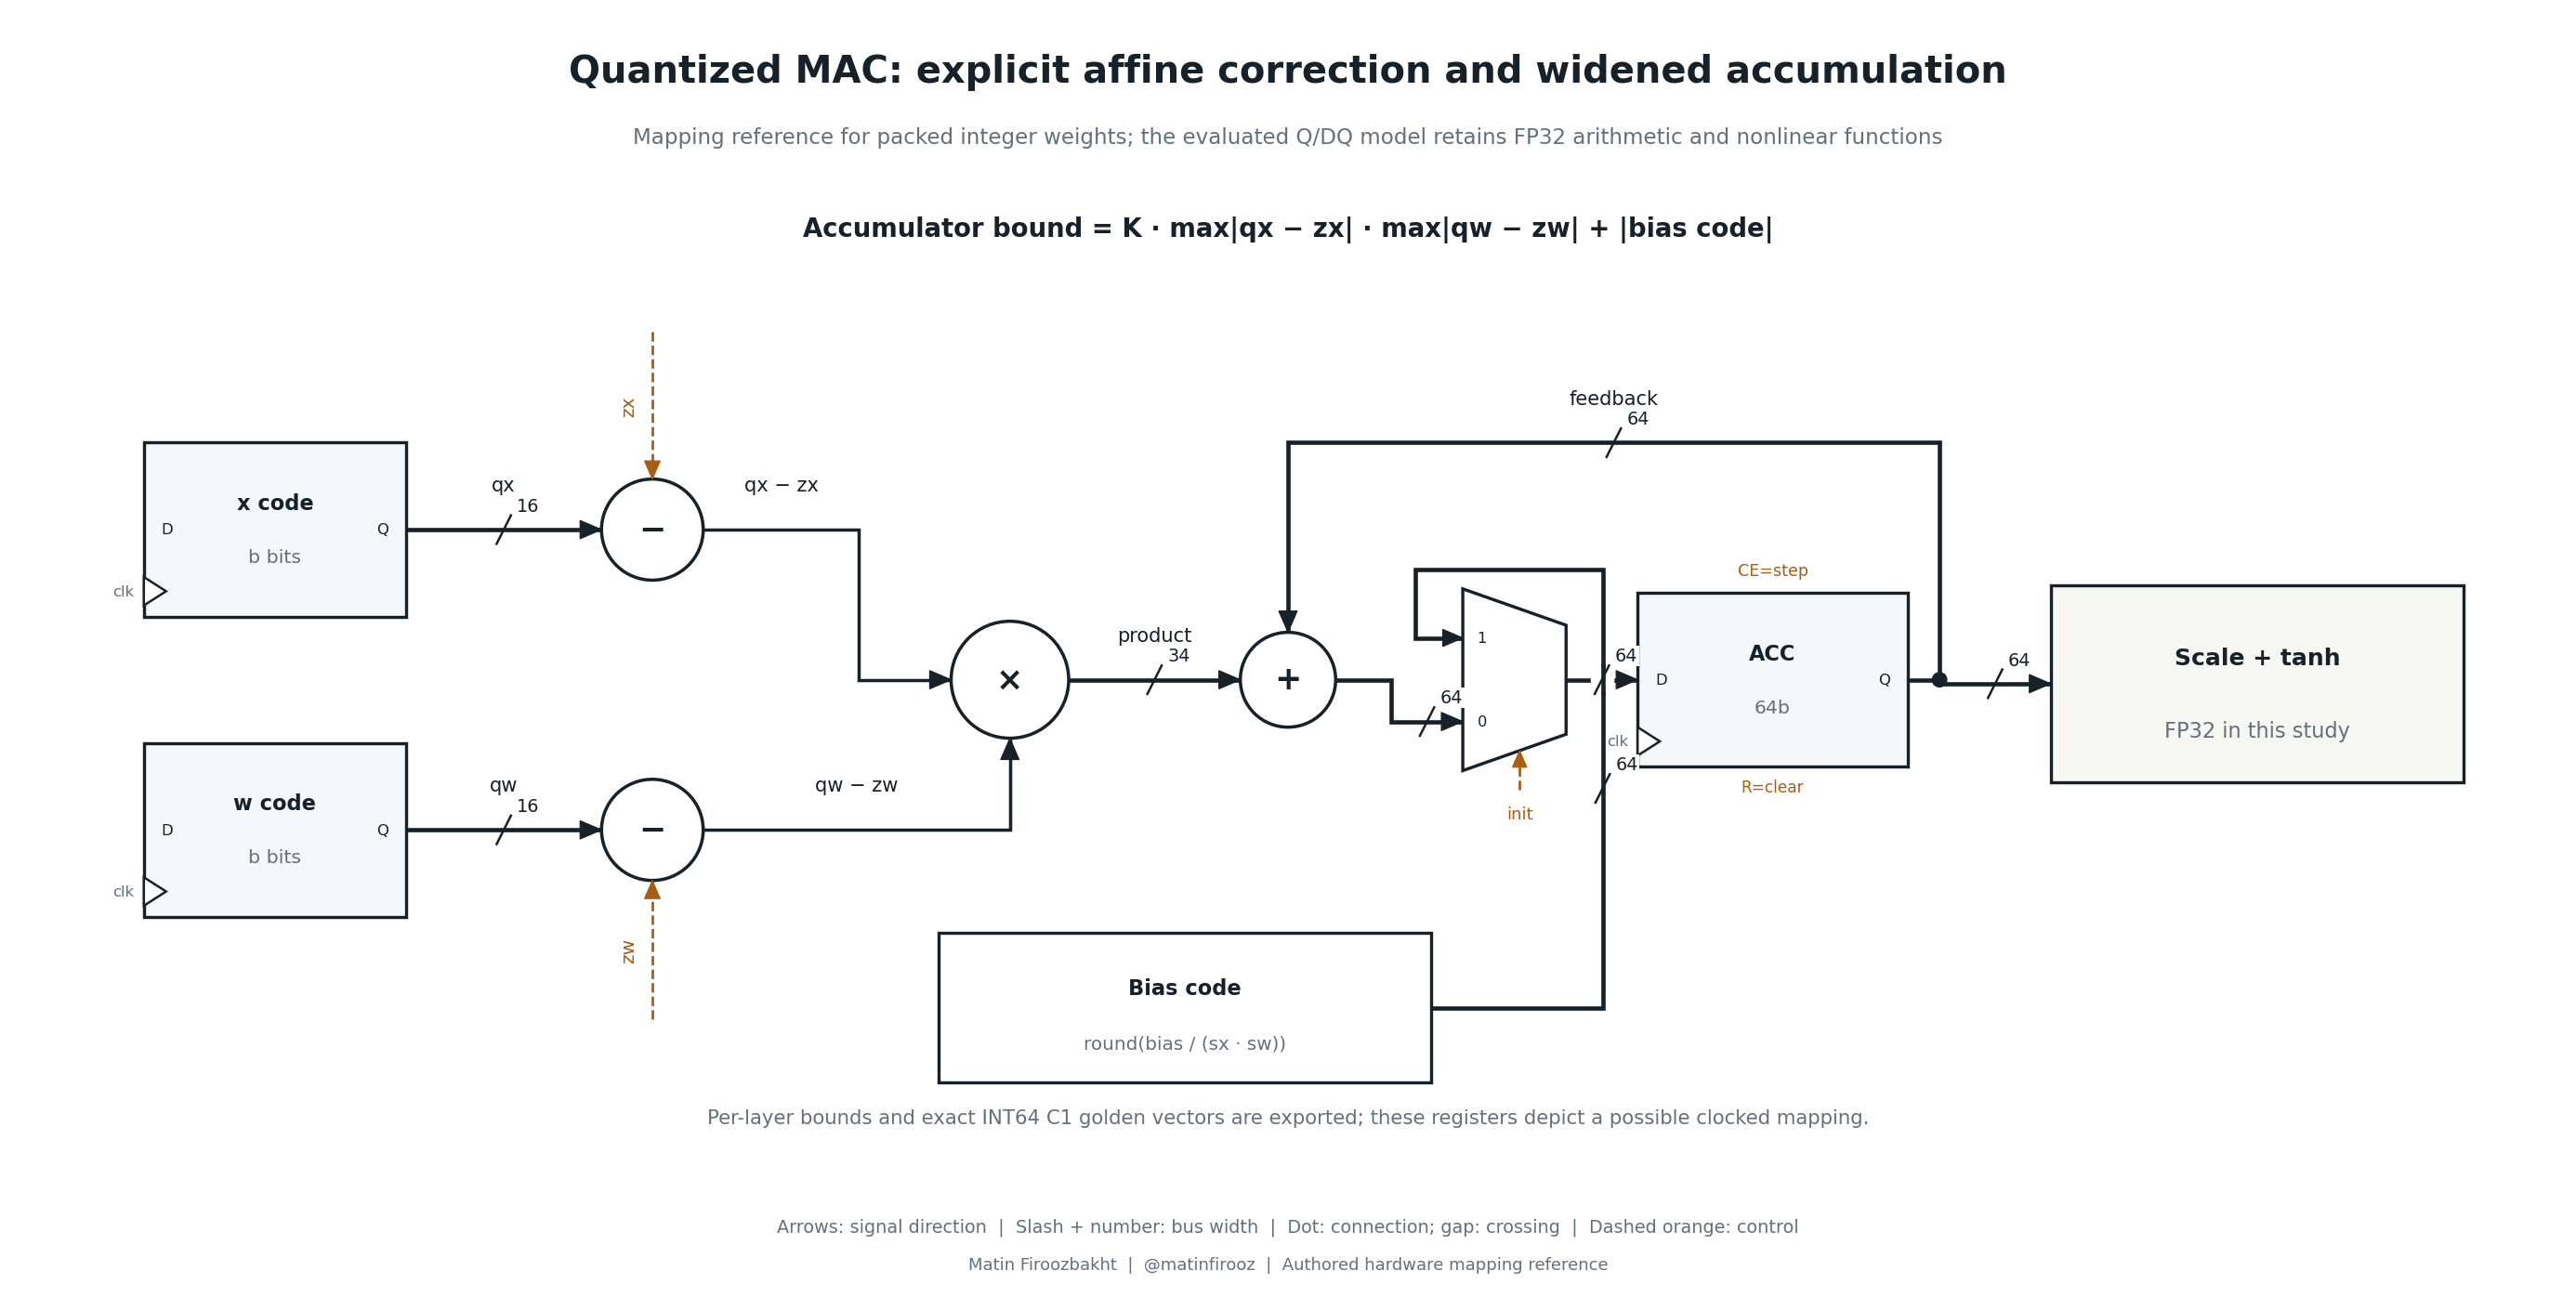

In [18]:
from software.exports import load_export
from software.quantization import integer_dot
export=ROOT/'hardware/exports/affine_int8'
restored, metadata=load_export(export)
state=torch.load(ROOT/'models/affine_int8_weights_only.pt',map_location='cpu',weights_only=True)['state_dict']
for name, value in restored.items():
    np.testing.assert_array_equal(value,state[name].numpy())
print('All five layers and biases reconstructed exactly from packed bytes.')
display(pd.DataFrame([{k:v for k,v in layer.items() if k in ['layer','shape','count','weight_byte_offset','weight_bytes','required_signed_accumulator_bits']} for layer in metadata['layers']]))
golden=np.load(export/'conv1_integer_golden.npz')
ap=metadata['activations']['input']; wp=metadata['layers'][0]['qparams']
actual=integer_dot(golden['input_codes'],golden['weight_codes'],ap['zero_point'],wp['zero_point'],golden['bias_codes'])
np.testing.assert_array_equal(actual,golden['accumulator'])
assert np.unique(golden['input_codes']).size>1
print('Central 5x5 input codes:',golden['input_codes'].reshape(5,5))
print('Exact centered INT64 MAC outputs:',actual.tolist())
print('Scaled preactivations:',golden['preactivation_reference'].tolist())
figure('hardware/figures/packed_weights.png')
figure('hardware/figures/quantized_datapath.png')


In [19]:
from software.packed_runtime import PackedLeNet
packed=PackedLeNet(ROOT/'hardware/exports/affine_int8')
probabilities=packed.probabilities(raw[:4])
display(pd.DataFrame(probabilities,columns=CLASSES))
packed_report=json.loads((ROOT/'results/quantization/packed_results.json').read_text())
assert packed_report['neural_network_imports']==[]
display(pd.DataFrame([{k:v for k,v in row.items() if k!='input_sha256'} for row in packed_report['results']]))
print('Full-test packed configurations evaluated:',len(packed_report['results']))
print('Prediction differences from saved PyTorch references:',sum(row['saved_torch_prediction_disagreements'] for row in packed_report['results']))


Full-test packed configurations evaluated: 16
Prediction differences from saved PyTorch references: 0


,T-shirt/top,Trouser,Pullover,Dress,Coat,Sandal,Shirt,Sneaker,Bag,Ankle boot
0,2.454448e-07,0.000008,0.000009,0.000006,0.000016,2.847211e-03,0.000001,3.995981e-03,1.071959e-05,9.931059e-01
1,6.018520e-04,0.000021,0.985441,0.000058,0.006442,5.805926e-05,0.007347,7.180658e-07,1.481116e-05,1.549333e-05
2,9.309305e-05,0.999662,0.000038,0.000163,0.000019,3.691927e-07,0.000006,1.442484e-05,1.745004e-06,1.400374e-06
3,1.776332e-05,0.999928,0.000007,0.000042,0.000001,6.615733e-08,0.000002,7.468573e-07,4.693226e-08,4.660006e-07


,bits,method,mode,n,correct,accuracy,cross_entropy,saved_torch_prediction_disagreements,saved_torch_max_logit_error
0,16,symmetric,weights_only,10000,8884,0.8884,0.311437,0,5.722046e-06
1,16,symmetric,weights_activations,10000,8884,0.8884,0.311438,0,4.110336e-04
2,16,affine,weights_only,10000,8884,0.8884,0.311439,0,6.675720e-06
3,16,affine,weights_activations,10000,8884,0.8884,0.311438,0,3.404617e-04
4,8,symmetric,weights_only,10000,8885,0.8885,0.310673,0,6.675720e-06
5,8,symmetric,weights_activations,10000,8882,0.8882,0.310920,0,1.060390e-01
6,8,affine,weights_only,10000,8884,0.8884,0.311381,0,6.675720e-06
7,8,affine,weights_activations,10000,8885,0.8885,0.311510,0,8.741283e-02
8,4,symmetric,weights_only,10000,8826,0.8826,0.329507,0,6.675720e-06
9,4,symmetric,weights_activations,10000,8626,0.8626,0.360430,0,1.923849e+00


In [20]:
answer_section(10)

## 10. CPU measurements

| Model | Median (µs/image) | P90 (µs/image) |
| --- | --- | --- |
| FP32 | 624.34 | 680.78 |
| FP16 | 790.06 | 869.14 |
| Native INT8 | 749.44 | 828.41 |
| 75% sparse weights, dense kernels | 633.38 | 693.52 |
| Compacted FP32 | 612.04 | 666.18 |

Host: **AMD EPYC 7763 64-Core Processor**. PyTorch 2.5.1+cpu, x86 quantized engine, 1 thread, batch 1, 100 warmup and 500 timed forwards. Median and P90 include Python dispatch on a shared CPU. These results are specific to this host and do not establish hardware energy, FPGA timing or a stable broad speedup. The lower dense MAC count of the compact model and the smaller packed payload are independent, directly measured structural properties.

![Latency](results/figures/latency.png)



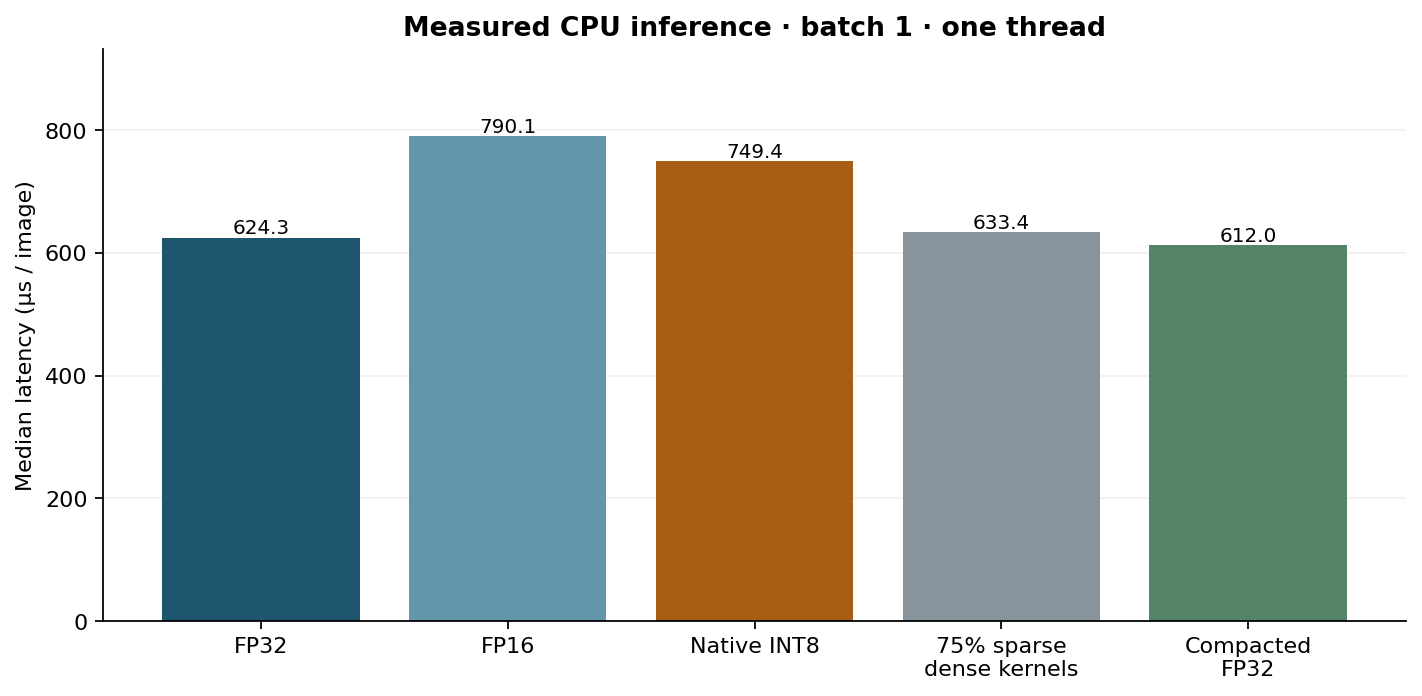

In [21]:
figure('results/figures/latency.png')

In [22]:
answer_section(11)

## 11. Verification, reproducibility and limitations

26 unit/integration tests cover exact example arrays, nearest-even ties, saturation, degenerate ranges, invalid inputs, zero representation, every code value at each packing width, odd-length packing, endianness, zero-point correction, data checksums and disjoint calibration, parameter/MAC counts, NumPy/PyTorch parity, all sixteen saved Q/DQ model reloads, converted INT8 operators, mask persistence, sparse round trips, channel compaction and full-test prediction counts. Added checks exercise the packed-model CLI, reject damaged binary grids/payloads, detect newly added source files and verify that report text follows changed measurements.

`results/evidence.json` binds computational sources, original compressed data, checkpoints, hardware exports and numeric measurements to SHA-256 digests. `scripts/verify_evidence.py` detects modified/missing inputs and newly added computational files; `--record` records completed experiments and must be used only after rerunning the affected computation. Generated prose and figures are outside this numeric-evidence hash scope. The notebook displays saved results after checking evidence and independently recomputes the FP32 test accuracy; its optional switches repeat full experiments.

Results describe one trained seed and a fixed calibration sample. There are no confidence intervals across independently trained models. Per-tensor min–max PTQ is intentionally simple; QAT, percentile clipping and learned scales are possible follow-up methods, not measured results here. FP32/F16/native INT8 are actual backend executions; other integer precisions describe simulated grids and real packed storage. All sources and checkpoints are included, and no runtime download is needed for evaluation.



In [23]:
if RUN_TESTS:
    test_run=subprocess.run([sys.executable,'-m','unittest','discover','-s','tests','-v'],cwd=ROOT,text=True,capture_output=True)
    print(test_run.stdout+test_run.stderr)
    assert test_run.returncode==0, 'A verification test failed.'
print('Evidence after notebook evaluation:',validate(ROOT))


test_all_result_counts_match_saved_full_test_predictions (test_project.ProjectTests.test_all_result_counts_match_saved_full_test_predictions) ... ok
test_binary_grid_and_payload_corruption_is_rejected (test_project.ProjectTests.test_binary_grid_and_payload_corruption_is_rejected) ... ok
test_compact_equivalence_and_propagated_shapes (test_project.ProjectTests.test_compact_equivalence_and_propagated_shapes) ... ok
test_dataset_checksums_and_disjoint_calibration (test_project.ProjectTests.test_dataset_checksums_and_disjoint_calibration) ... ok
test_documentation_uses_changed_experiment_metrics (test_project.ProjectTests.test_documentation_uses_changed_experiment_metrics) ... ok
test_every_packed_export_reloads_to_evaluated_weights (test_project.ProjectTests.test_every_packed_export_reloads_to_evaluated_weights) ... ok
test_evidence_detects_new_and_changed_computational_inputs (test_project.ProjectTests.test_evidence_detects_new_and_changed_computational_inputs) ... ok
test_manual_process

In [24]:
answer_section(12)

## 12. Primary references and supplied materials

1. Supplied [HW4.pdf](docs/HW4.pdf) and [original assignment README](docs/assignment_README.md).
2. Fashion-MNIST authors' [repository, dataset and license](https://github.com/zalandoresearch/fashion-mnist).
3. PyTorch 2.5.1 [FakeQuantize source](https://github.com/pytorch/pytorch/blob/v2.5.1/torch/ao/quantization/fake_quantize.py) and [observer source](https://github.com/pytorch/pytorch/blob/v2.5.1/torch/ao/quantization/observer.py). The pinned runtime is tested directly; current documentation may describe newer APIs.
4. PyTorch [official pruning tutorial](https://docs.pytorch.org/tutorials/intermediate/pruning_tutorial.html).
5. M. Horowitz, “Computing’s energy problem (and what we can do about it),” ISSCC 2014, [DOI:10.1109/ISSCC.2014.6757323](https://doi.org/10.1109/ISSCC.2014.6757323). Historical context, not a PPA measurement of this project.
6. A. Gholami et al., [A Survey of Quantization Methods for Efficient Neural Network Inference](https://arxiv.org/abs/2103.13630), 2021. Background reference from the supplied assignment.


# Complete implementation source

The listings below are the exact sources used by this notebook and included in the ZIP. Step 1 is isolated in the manual quantization, NumPy inference and data modules. Training, PyTorch PTQ and pruning are separate. These listings are displayed as source rather than silently rerunning long training jobs.


## Source: software/quantization.py

In [25]:
display(Code(filename=str(ROOT/'software/quantization.py'), language='python'))

"""Manual quantization. This module and its dependencies never import PyTorch."""
from dataclasses import dataclass, asdict
import math
import numpy as np

METHODS=('symmetric','affine','endpoint')
SAMPLE=np.array([43.21,-44.93,0,22.99,-43.93,-11.35,38.48,-20.49,-38.61,-28.02],dtype=np.float64)

@dataclass(frozen=True)
class QParams:
    bits:int
    method:str
    scale:float
    zero_point:int
    qmin:int
    qmax:int
    offset:float=0.0
    def to_dict(self):return asdict(self)

def parameters(x,bits,method='symmetric'):
    x=np.asarray(x,dtype=np.float64)
    if not isinstance(bits,(int,np.integer)) or isinstance(bits,bool) or not 2<=bits<=16:raise ValueError('bits must be an integer in 2..16')
    if method not in METHODS:raise ValueError('unknown method')
    if not x.size or not np.isfinite(x).all():raise ValueError('nonempty finite values required')
    lo=float(x.min());hi=float(x.max())
    if method=='symmetric':
        m=(1<<(int(bits)-1))-1;scale=max(abs(lo),abs(hi))/m
        return QParams(int(bits),method,scale if scale>0 else 1.0,0,-m,m)
    maxcode=(1<<int(bits))-1
    if method=='endpoint':
        # Literal shifted min-max equation from the assignment; NOT an integer-zero-point grid.
        scale=(hi-lo)/maxcode if hi>lo else 1.0
        return QParams(int(bits),method,scale,int(np.clip(np.rint(-lo/scale),0,maxcode)),0,maxcode,lo)
    lo=min(lo,0.0);hi=max(hi,0.0);scale=(hi-lo)/maxcode if hi>lo else 1.0
    z=int(np.clip(np.rint(-lo/scale),0,maxcode))
    return QParams(int(bits),method,scale,z,0,maxcode)

def quantize(x,p):
    x=np.asarray(x)
    if not np.isfinite(x).all():raise ValueError('nonfinite input')
    value=np.rint((x.astype(np.float64)-p.offset)/p.scale) if p.method=='endpoint' else np.rint(x.astype(np.float64)/p.scale)+p.zero_point
    return np.clip(value,p.qmin,p.qmax).astype(np.int32)

def dequantize(q,p,dtype=np.float32):
    q=np.asarray(q,dtype=np.float64)
    value=q*p.scale+p.offset if p.method=='endpoint' else (q-p.zero_point)*p.scale
    return value.astype(dtype)

def qdq(x,p):return dequantize(quantize(x,p),p)

def pack_codes(q,bits,signed):
    """C-order, first code in least significant bits; little-endian for 16 bits."""
    q=np.asarray(q,dtype=np.int64).ravel()
    low=-(1<<(bits-1)) if signed else 0;high=(1<<(bits-1))-1 if signed else (1<<bits)-1
    if bits not in (2,4,8,16) or np.any(q<low) or np.any(q>high):raise ValueError('unrepresentable code')
    u=q&((1<<bits)-1)
    if bits==16:return u.astype('<u2').tobytes()
    per=8//bits;out=np.zeros((len(q)+per-1)//per,dtype=np.uint8)
    for lane in range(per):
        part=u[lane::per].astype(np.uint8);out[:len(part)]|=part<<(bits*lane)
    return out.tobytes()

def unpack_codes(blob,bits,count,signed):
    if bits not in (2,4,8,16) or count<0 or len(blob)!=(count*bits+7)//8:raise ValueError('invalid packed length')
    if bits==16:u=np.frombuffer(blob,dtype='<u2').astype(np.int32)
    else:
        a=np.frombuffer(blob,dtype=np.uint8);per=8//bits
        u=np.stack([(a>>(i*bits))&((1<<bits)-1) for i in range(per)],1).reshape(-1)[:count].astype(np.int32)
    if signed:u=np.where(u&(1<<(bits-1)),u-(1<<bits),u)
    return u

def integer_dot(xq,wq,zx,zw,bias=0):
    """Exact widened reference with affine zero-point correction."""
    return (np.asarray(xq,dtype=np.int64)-zx)@(np.asarray(wq,dtype=np.int64)-zw).T+np.asarray(bias,dtype=np.int64)

def required_signed_bits(max_abs):
    return max(2,int(max_abs).bit_length()+1)

## Source: software/numpy_lenet.py

In [26]:
display(Code(filename=str(ROOT/'software/numpy_lenet.py'), language='python'))

"""LeNet inference using NumPy only, including optional calibrated activation Q/DQ."""
from pathlib import Path
import numpy as np
from numpy.lib.stride_tricks import sliding_window_view
from .quantization import parameters,qdq

LAYERS=('conv1','conv3','conv5','fc6','fc7')
POINTS=('input','t1','p1','t3','p3','t5','t6','logits')
INPUT_POINT={'conv1':'input','conv3':'p1','conv5':'p3','fc6':'t5','fc7':'t6'}

def prepare_pixels(raw):return np.pad(np.asarray(raw,dtype=np.float32)[:,None]/255,((0,0),(0,0),(2,2),(2,2)))

def convolution(x,w,b):
    n,c,h,ww=x.shape;o,_,kh,kw=w.shape
    v=sliding_window_view(x,(kh,kw),axis=(2,3))
    col=np.ascontiguousarray(v.transpose(0,2,3,1,4,5)).reshape(-1,c*kh*kw)
    out=col@w.reshape(o,-1).T+b
    return out.reshape(n,h-kh+1,ww-kw+1,o).transpose(0,3,1,2)

def pool(x):
    n,c,h,w=x.shape
    return x.reshape(n,c,h//2,2,w//2,2).mean((3,5),dtype=np.float32)

def forward(x,weights,activations=None,observe=None):
    def at(name,value):
        if observe is not None:observe(name,value)
        return qdq(value,activations[name]) if activations is not None else value
    def conv(name,x):return convolution(x,weights[name+'.weight'],weights[name+'.bias'])
    def dense(name,x):return x@weights[name+'.weight'].T+weights[name+'.bias']
    x=at('input',x);x=at('t1',np.tanh(conv('conv1',x)))
    x=at('p1',np.tanh(pool(x)));x=at('t3',np.tanh(conv('conv3',x)))
    x=at('p3',np.tanh(pool(x)));x=at('t5',np.tanh(conv('conv5',x)).reshape(len(x),-1))
    x=at('t6',np.tanh(dense('fc6',x)));return at('logits',dense('fc7',x))

def calibrate(raw,weights,batch=128):
    ranges={n:[float('inf'),-float('inf')] for n in POINTS}
    def observe(name,x):ranges[name][0]=min(ranges[name][0],float(x.min()));ranges[name][1]=max(ranges[name][1],float(x.max()))
    for begin in range(0,len(raw),batch):forward(prepare_pixels(raw[begin:begin+batch]),weights,observe=observe)
    return ranges

def activation_parameters(ranges,bits,method):return {n:parameters(v,bits,method) for n,v in ranges.items()}

def quantized_weights(weights,bits,method):
    params={};out={}
    for name,value in weights.items():
        if name.endswith('.weight'):params[name]=parameters(value,bits,method);out[name]=qdq(value,params[name])
        else:out[name]=value.astype(np.float32).copy()
    return out,params

def evaluate(raw,labels,weights,activations=None,batch=128):
    parts=[]
    for begin in range(0,len(raw),batch):parts.append(forward(prepare_pixels(raw[begin:begin+batch]),weights,activations))
    logits=np.concatenate(parts);pred=logits.argmax(1);shift=logits-logits.max(1,keepdims=True)
    loss=float(np.mean(np.log(np.exp(shift).sum(1))-shift[np.arange(len(labels)),labels]))
    return {'n':len(labels),'correct':int(np.sum(pred==labels)),'accuracy':float(np.mean(pred==labels)),'cross_entropy':loss},logits

## Source: software/data.py

In [27]:
display(Code(filename=str(ROOT/'software/data.py'), language='python'))

"""Official Fashion-MNIST IDX files, verified downloads and disjoint splits."""
import gzip
import hashlib
import json
import struct
import urllib.request
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np

FILES={
 'train-images-idx3-ubyte.gz':'8d4fb7e6c68d591d4c3dfef9ec88bf0d',
 'train-labels-idx1-ubyte.gz':'25c81989df183df01b3e8a0aad5dffbe',
 't10k-images-idx3-ubyte.gz':'bef4ecab320f06d8554ea6380940ec79',
 't10k-labels-idx1-ubyte.gz':'bb300cfdad3c16e7a12a480ee83cd310',
}
BASE='https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/'
CLASSES=['T-shirt/top','Trouser','Pullover','Dress','Coat','Sandal','Shirt','Sneaker','Bag','Ankle boot']

def download(root):
    root=Path(root);root.mkdir(parents=True,exist_ok=True)
    def one(item):
        name,expected=item;p=root/name
        if not p.exists():
            with urllib.request.urlopen(BASE+name,timeout=90) as response:p.write_bytes(response.read())
        data=p.read_bytes()
        if hashlib.md5(data).hexdigest()!=expected:raise ValueError('Checksum mismatch: '+name)
        if name.startswith('t10k'): (root/name.removesuffix('.gz')).write_bytes(gzip.decompress(data))
        return {'file':name,'source':BASE+name,'bytes':len(data),'md5':expected,'sha256':hashlib.sha256(data).hexdigest()}
    with ThreadPoolExecutor(max_workers=4) as pool:manifest=list(pool.map(one,FILES.items()))
    (root/'manifest.json').write_text(json.dumps(manifest,indent=2))
    return manifest

def load_idx(root,kind='train'):
    root=Path(root)
    image=gzip.decompress((root/(kind+'-images-idx3-ubyte.gz')).read_bytes())
    label=gzip.decompress((root/(kind+'-labels-idx1-ubyte.gz')).read_bytes())
    magic,n,h,w=struct.unpack('>4I',image[:16]);lm,ln=struct.unpack('>2I',label[:8])
    if (magic,lm,h,w)!=(2051,2049,28,28) or n!=ln:raise ValueError('Invalid IDX header')
    x=np.frombuffer(image,dtype=np.uint8,offset=16).reshape(n,28,28).copy()
    y=np.frombuffer(label,dtype=np.uint8,offset=8).copy()
    if len(image)!=16+n*784 or len(label)!=8+n or y.max()>9:raise ValueError('Invalid IDX payload')
    return x,y

def split_indices(labels,seed=42):
    rng=np.random.default_rng(seed);train=[];valid=[]
    for c in range(10):
        indexes=np.flatnonzero(labels==c);rng.shuffle(indexes)
        valid.extend(indexes[:600]);train.extend(indexes[600:])
    return np.sort(np.array(train,dtype=np.int64)),np.sort(np.array(valid,dtype=np.int64))

## Source: software/model.py

In [28]:
display(Code(filename=str(ROOT/'software/model.py'), language='python'))

"""Dense LeNet-5 variant with tanh, average pooling and a ten-logit head."""
import torch
from torch import nn

class LeNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1=nn.Conv2d(1,6,5)
        self.conv3=nn.Conv2d(6,16,5)
        self.conv5=nn.Conv2d(16,120,5)
        self.fc6=nn.Linear(120,84)
        self.fc7=nn.Linear(84,10)
    def forward(self,x):
        x=torch.tanh(self.conv1(x))
        x=torch.tanh(nn.functional.avg_pool2d(x,2))
        x=torch.tanh(self.conv3(x))
        x=torch.tanh(nn.functional.avg_pool2d(x,2))
        x=torch.tanh(self.conv5(x)).flatten(1)
        return self.fc7(torch.tanh(self.fc6(x)))
    def probabilities(self,x):
        return torch.softmax(self(x),dim=1)

def prepare_pixels(raw):
    x=torch.as_tensor(raw.copy()).float().unsqueeze(1)/255.0
    return nn.functional.pad(x,(2,2,2,2),value=0.0)

## Source: scripts/train.py

In [29]:
display(Code(filename=str(ROOT/'scripts/train.py'), language='python'))

"""Train on 54,000 images, select by 6,000 validation images, evaluate official test once."""
import argparse
import csv
import hashlib
import json
import os
import platform
import sys
from pathlib import Path
from time import perf_counter

ROOT=Path(__file__).resolve().parents[1];sys.path.insert(0,str(ROOT))
import numpy as np
import torch
from software.data import download,load_idx,split_indices
from software.model import LeNet,prepare_pixels

def evaluate(model,x,y,batch=512):
    model.eval();loss=correct=0;parts=[]
    with torch.inference_mode():
        for begin in range(0,len(y),batch):
            logits=model(x[begin:begin+batch]);target=y[begin:begin+batch]
            loss+=torch.nn.functional.cross_entropy(logits,target,reduction='sum').item()
            correct+=(logits.argmax(1)==target).sum().item();parts.append(logits.numpy())
    return {'n':len(y),'correct':correct,'accuracy':correct/len(y),'cross_entropy':loss/len(y)},np.concatenate(parts)

def main():
    parser=argparse.ArgumentParser();parser.add_argument('--epochs',type=int,default=20);parser.add_argument('--threads',type=int,default=4);args=parser.parse_args()
    torch.set_num_threads(args.threads);torch.set_num_interop_threads(1)
    torch.manual_seed(7);np.random.seed(7);torch.use_deterministic_algorithms(True)
    download(ROOT/'data/fashion');raw,labels=load_idx(ROOT/'data/fashion');ti,vi=split_indices(labels)
    np.savez(ROOT/'results/software/split_indices.npz',train=ti,validation=vi)
    allx=prepare_pixels(raw);ally=torch.tensor(labels,dtype=torch.long)
    x,y=allx[ti],ally[ti];vx,vy=allx[vi],ally[vi]
    model=LeNet();count=sum(p.numel() for p in model.parameters());assert count==61706
    optimizer=torch.optim.AdamW(model.parameters(),lr=.001,weight_decay=.0001)
    scheduler=torch.optim.lr_scheduler.MultiStepLR(optimizer,milestones=[10,16],gamma=.5)
    rng=torch.Generator().manual_seed(42);history=[];best=float('inf');best_epoch=0;started=perf_counter()
    for epoch in range(1,args.epochs+1):
        mark=perf_counter();model.train();loss=correct=0;order=torch.randperm(len(y),generator=rng)
        for begin in range(0,len(y),256):
            idx=order[begin:begin+256];optimizer.zero_grad(set_to_none=True)
            logits=model(x[idx]);value=torch.nn.functional.cross_entropy(logits,y[idx]);value.backward();optimizer.step()
            loss+=value.item()*len(idx);correct+=(logits.detach().argmax(1)==y[idx]).sum().item()
        val,_=evaluate(model,vx,vy)
        record={'epoch':epoch,'train_cross_entropy':loss/len(y),'train_accuracy':correct/len(y),'validation_cross_entropy':val['cross_entropy'],'validation_accuracy':val['accuracy'],'learning_rate':optimizer.param_groups[0]['lr'],'seconds':perf_counter()-mark}
        history.append(record)
        if val['cross_entropy']<best:
            best=val['cross_entropy'];best_epoch=epoch
            torch.save({'state_dict':model.state_dict(),'author':'Matin Firoozbakht','github':'https://github.com/matinfirooz','epoch':epoch,'architecture':'32x32 -> C1/S2/C3/S4/C5/F6/F7'},ROOT/'software/lenet_fashion_mnist.pt')
        scheduler.step();print(json.dumps(record),flush=True)
        (ROOT/'results/software/training_history.json').write_text(json.dumps(history,indent=2))
    checkpoint=torch.load(ROOT/'software/lenet_fashion_mnist.pt',map_location='cpu',weights_only=True);model.load_state_dict(checkpoint['state_dict'])
    np.savez_compressed(ROOT/'software/trained_weights.npz',**{k:v.detach().numpy() for k,v in model.state_dict().items()})
    test_raw,test_labels=load_idx(ROOT/'data/fashion','t10k');test_x=prepare_pixels(test_raw);test_y=torch.tensor(test_labels,dtype=torch.long)
    test,logits=evaluate(model,test_x,test_y);validation,_=evaluate(model,vx,vy)
    np.savez_compressed(ROOT/'results/software/float_test_outputs.npz',logits=logits,labels=test_labels,predictions=logits.argmax(1))
    with (ROOT/'results/software/training_history.csv').open('w',newline='') as f:
        writer=

## Source: scripts/run_manual.py

In [30]:
display(Code(filename=str(ROOT/'scripts/run_manual.py'), language='python'))

"""Step 1 runs in a separate NumPy-only process; never imports a neural network library."""
import json,sys,time
from pathlib import Path
ROOT=Path(__file__).resolve().parents[1];sys.path.insert(0,str(ROOT))
import numpy as np
from software.data import load_idx,split_indices
from software.quantization import SAMPLE,parameters,quantize,dequantize
from software.numpy_lenet import calibrate,activation_parameters,quantized_weights,evaluate

def main():
    start=time.perf_counter();r=ROOT/'results/quantization';r.mkdir(parents=True,exist_ok=True)
    weights=dict(np.load(ROOT/'software/trained_weights.npz'));raw,labels=load_idx(ROOT/'data/fashion','t10k')
    train,ty=load_idx(ROOT/'data/fashion');ti,vi=split_indices(ty)
    rng=np.random.default_rng(101);ci=np.sort(rng.choice(ti,1000,replace=False))
    np.save(ROOT/'results/software/calibration_indices.npy',ci)
    ranges=calibrate(train[ci],weights);(r/'calibration_ranges.json').write_text(json.dumps(ranges,indent=2))
    sample=[]
    for method in ['symmetric','endpoint','affine']:
        for bits in [16,8,4]:
            p=parameters(SAMPLE,bits,method);q=quantize(SAMPLE,p);dq=dequantize(q,p,dtype=np.float64)
            sample.append({'method':method,'bits':bits,**p.to_dict(),'q':q.tolist(),'dequantized':dq.tolist(),'mse':float(np.mean((dq-SAMPLE)**2)),'max_error':float(np.max(abs(dq-SAMPLE)))})
    (r/'worked_example.json').write_text(json.dumps(sample,indent=2))
    baseline,logits=evaluate(raw,labels,weights)
    ref=np.load(ROOT/'results/software/float_test_outputs.npz')['logits']
    baseline['torch_max_logit_error']=float(np.max(abs(logits-ref)));baseline['torch_prediction_disagreements']=int(np.sum(logits.argmax(1)!=ref.argmax(1)))
    np.savez_compressed(r/'numpy_fp32_predictions.npz',logits=logits,labels=labels)
    results=[]
    for bits in [16,8,4]:
        for method in ['symmetric','affine','endpoint']:
            qw,wp=quantized_weights(weights,bits,method)
            for mode in ['weights_only','weights_activations']:
                ap=activation_parameters(ranges,bits,method) if mode=='weights_activations' else None
                result,out=evaluate(raw,labels,qw,ap)
                row={'method':method,'bits':bits,'mode':mode,**result};results.append(row);print(json.dumps(row),flush=True)
                np.savez_compressed(r/f'numpy_{method}_{bits}_{mode}.npz',logits=out,predictions=out.argmax(1))
    result={'status':'completed','baseline':baseline,'results':results,'seconds':time.perf_counter()-start,'calibration_images':1000,'calibration_seed':101,'numpy_version':np.__version__,'neural_network_imports':[n for n in sys.modules if n.split('.')[0] in ['torch','tensorflow','jax','keras']]}
    assert not result['neural_network_imports'];assert baseline['torch_prediction_disagreements']==0
    (r/'manual_results.json').write_text(json.dumps(result,indent=2));print('FINAL',json.dumps(result),flush=True)
if __name__=='__main__':main()

## Source: software/torch_quantization.py

In [31]:
display(Code(filename=str(ROOT/'software/torch_quantization.py'), language='python'))

"""PyTorch PTQ Q/DQ experiments plus a real converted CPU INT8 model."""
import copy
import torch
from torch import nn
from torch.ao.quantization import (FakeQuantize,MinMaxObserver,QuantStub,DeQuantStub,
                                  QConfig,PerChannelMinMaxObserver,prepare,convert)
from .model import LeNet
from .numpy_lenet import POINTS,LAYERS
from .quantization import QParams

def make_fake(bits,method):
    maximum=2**(bits-1)-1 if method=='symmetric' else 2**bits-1
    dtype=torch.qint32 if bits==16 else (torch.qint8 if method=='symmetric' else torch.quint8)
    return FakeQuantize(observer=MinMaxObserver,dtype=dtype,
        qscheme=torch.per_tensor_symmetric if method=='symmetric' else torch.per_tensor_affine,
        quant_min=-maximum if method=='symmetric' else 0,quant_max=maximum)

def describe(f,bits,method):
    return QParams(bits,method,float(f.scale.item()),int(f.zero_point.item()),f.quant_min,f.quant_max)

def weight_qdq(model,bits,method):
    model=copy.deepcopy(model).eval();params={};codes={}
    with torch.no_grad():
        for name,module in model.named_modules():
            if isinstance(module,(nn.Conv2d,nn.Linear)):
                f=make_fake(bits,method);value=f(module.weight.detach());f.disable_observer()
                p=describe(f,bits,method);q=torch.clamp(torch.round(value/f.scale)+f.zero_point,p.qmin,p.qmax).to(torch.int32)
                module.weight.copy_(value);params[name+'.weight']=p;codes[name+'.weight']=q.numpy()
    return model,params,codes

def calibrated_activations(ranges,bits,method):
    params={}
    for name in POINTS:
        f=make_fake(bits,method);f(torch.tensor(ranges[name],dtype=torch.float32));f.disable_observer()
        params[name]=describe(f,bits,method)
    return params

class QDQLeNet(nn.Module):
    """Integer grids are simulated; convolution, pooling and tanh still compute in FP32."""
    def __init__(self,net,activations=None):super().__init__();self.net=net;self.activations=activations
    def at(self,name,x):
        if self.activations is None:return x
        p=self.activations[name]
        return torch.fake_quantize_per_tensor_affine(x,p.scale,p.zero_point,p.qmin,p.qmax)
    def forward(self,x):
        m=self.net;x=self.at('input',x);x=self.at('t1',torch.tanh(m.conv1(x)))
        x=self.at('p1',torch.tanh(nn.functional.avg_pool2d(x,2)))
        x=self.at('t3',torch.tanh(m.conv3(x)));x=self.at('p3',torch.tanh(nn.functional.avg_pool2d(x,2)))
        x=self.at('t5',torch.tanh(m.conv5(x)).flatten(1));x=self.at('t6',torch.tanh(m.fc6(x)))
        return self.at('logits',m.fc7(x))

class NativeINT8(nn.Module):
    def __init__(self,net=None):
        super().__init__();self.quant=QuantStub();self.net=LeNet() if net is None else copy.deepcopy(net);self.dequant=DeQuantStub()
    def forward(self,x):return self.dequant(self.net(self.quant(x)))

def convert_native(net,calibration,engine='x86'):
    if engine not in torch.backends.quantized.supported_engines:raise RuntimeError('INT8 engine unavailable: '+engine)
    torch.backends.quantized.engine=engine;m=NativeINT8(net).eval()
    m.qconfig=QConfig(activation=MinMaxObserver.with_args(dtype=torch.quint8,qscheme=torch.per_tensor_affine,quant_min=0,quant_max=255),
                     weight=PerChannelMinMaxObserver.with_args(dtype=torch.qint8,qscheme=torch.per_channel_symmetric,quant_min=-128,quant_max=127))
    prepare(m,inplace=True)
    with torch.inference_mode():
        for x in calibration:m(x)
    convert(m,inplace=True);return m

def load_qdq(path):
    d=torch.load(path,map_location='cpu',weights_only=True);m=LeNet();m.load_state_dict(d['state_dict'])
    ap={k:QParams(**v) for k,v in d['activations'].items()} if d.get('activations') else None
    return QDQLeNet(m,ap).eval()

## Source: scripts/run_pytorch.py

In [32]:
display(Code(filename=str(ROOT/'scripts/run_pytorch.py'), language='python'))

"""Step 2: measured FP32, true FP16, custom-grid PyTorch PTQ, and native INT8."""
import json,sys,copy,time
from pathlib import Path
ROOT=Path(__file__).resolve().parents[1];sys.path.insert(0,str(ROOT))
import numpy as np
import torch
from software.data import load_idx
from software.model import LeNet,prepare_pixels
from software.torch_quantization import weight_qdq,calibrated_activations,QDQLeNet,convert_native
from software.exports import export_weights,export_floating,export_native
from scripts.train import evaluate

def main():
    torch.set_num_threads(4);torch.set_num_interop_threads(1);torch.manual_seed(7)
    d=ROOT/'results/quantization';d.mkdir(exist_ok=True);start=time.perf_counter()
    state=torch.load(ROOT/'software/lenet_fashion_mnist.pt',map_location='cpu',weights_only=True);model=LeNet().eval();model.load_state_dict(state['state_dict'])
    raw,labels=load_idx(ROOT/'data/fashion','t10k');x=prepare_pixels(raw);y=torch.tensor(labels,dtype=torch.long)
    train,_=load_idx(ROOT/'data/fashion');ci=np.load(ROOT/'results/software/calibration_indices.npy');cx=prepare_pixels(train[ci]);ranges=json.loads((d/'calibration_ranges.json').read_text())
    results=[];payload=61706*4
    base,out=evaluate(model,x,y);results.append({'name':'FP32','method':'float','bits':32,'mode':'floating_point','execution':'native FP32','payload_bytes':payload,'compression_ratio':1,**base})
    half=copy.deepcopy(model).half();half_result,hout=evaluate(half,x.half(),y)
    torch.save({'state_dict':half.state_dict(),'precision':'FP16','author':'Matin Firoozbakht'},ROOT/'models/fp16.pt')
    np.savez_compressed(d/'fp16_predictions.npz',logits=hout,predictions=hout.argmax(1))
    results.append({'name':'FP16','method':'float','bits':16,'mode':'floating_point','execution':'native FP16 CPU','payload_bytes':61706*2,'compression_ratio':2,**half_result})
    export_floating(ROOT/'hardware/exports/fp32',{n:v.detach().numpy() for n,v in model.state_dict().items()},32)
    export_floating(ROOT/'hardware/exports/fp16',{n:v.detach().numpy() for n,v in half.state_dict().items()},16)
    native_export={}
    for bits in [16,8,4,2]:
        for method in ['symmetric','affine']:
            net,wp,codes=weight_qdq(model,bits,method);ap=calibrated_activations(ranges,bits,method)
            weights={n:v.detach().numpy() for n,v in net.state_dict().items()}
            metadata=export_weights(ROOT/f'hardware/exports/{method}_int{bits}',weights,wp,codes,ap,raw[0]);native_export[f'{method}_{bits}']=metadata
            for mode in ['weights_only','weights_activations']:
                a=ap if mode=='weights_activations' else None;qmodel=QDQLeNet(net,a).eval();result,out=evaluate(qmodel,x,y)
                parameter_bytes=metadata['full_qdq_parameter_bytes'] if a else metadata['payload_bytes']
                row={'name':f'INT{bits}','method':method,'bits':bits,'mode':mode,'execution':'FP32 Q/DQ simulation','payload_bytes':parameter_bytes,'compression_ratio':payload/parameter_bytes,**result};results.append(row);print(json.dumps(row),flush=True)
                p=ROOT/f'models/{method}_int{bits}_{mode}.pt'
                torch.save({'state_dict':net.state_dict(),'bits':bits,'method':method,'mode':mode,'activations':{k:v.to_dict() for k,v in a.items()} if a else None,'weight_qparams':{k:v.to_dict() for k,v in wp.items()},'export':f'hardware/exports/{method}_int{bits}','author':'Matin Firoozbakht'},p)
                np.savez_compressed(d/f'torch_{method}_{bits}_{mode}.npz',logits=out,predictions=out.argmax(1))
    native=convert_native(model,[cx[i:i+128] for i in range(0,len(cx),128)])
    result,out=evaluate(native,x,y)
    export_native(ROOT/'hardware/exports/native_int8',native)
    torch.save({'state_dict':native.state_dict(),'engine':torch.backends.quantized.engine,'author':'Matin Firoozbakht'},ROOT/'models/native_int8.pt')
    converted=[]
    for name,module in native.named_modules():
        if isinstance(module,(torch.ao.nn.quantized.Conv2d,torch.ao.nn.q

## Source: software/exports.py

In [33]:
display(Code(filename=str(ROOT/'software/exports.py'), language='python'))

"""Deterministic, round-trip-checked hardware weight images. NumPy only."""
import hashlib,json,struct
from pathlib import Path
import numpy as np
from .quantization import pack_codes,unpack_codes,dequantize,quantize,integer_dot,required_signed_bits,QParams
from .numpy_lenet import LAYERS,INPUT_POINT,prepare_pixels

def export_weights(root,weights,params,codes,activations=None,raw_example=None):
    root=Path(root);root.mkdir(parents=True,exist_ok=True)
    wb=bytearray();bb=bytearray();qb=bytearray();rows=[]
    for name in LAYERS:
        key=name+'.weight';q=codes[key];p=params[key];value=weights[key];bias=weights[name+'.bias']
        blob=pack_codes(q,p.bits,p.qmin<0);offset=len(wb);wb.extend(blob)
        restored=unpack_codes(blob,p.bits,q.size,p.qmin<0).reshape(q.shape);assert np.array_equal(restored,q)
        err=float(np.max(abs(dequantize(q,p)-value)));assert err<2e-6,(key,err)
        bo=len(bb);bb.extend(np.asarray(bias,dtype='<f4').tobytes())
        # Binary qparam record is float64 scale, int32 zero, float64 offset: 20 bytes per layer.
        import struct
        qo=len(qb);qb.extend(struct.pack('<did',p.scale,p.zero_point,p.offset))
        row={'layer':name,'shape':list(q.shape),'layout':'OIHW' if q.ndim==4 else 'OI','count':q.size,'weight_byte_offset':offset,'weight_bytes':len(blob),
             'bias_byte_offset':bo,'bias_count':bias.size,'qparam_byte_offset':qo,'qparams':p.to_dict(),'dq_max_error':err}
        if activations is not None:
            ap=activations[INPUT_POINT[name]];ib=np.rint(bias.astype(np.float64)/(ap.scale*p.scale)).astype('<i8')
            (root/(name+'_bias_i64.bin')).write_bytes(ib.tobytes())
            k=int(np.prod(q.shape[1:]));maxx=max(abs(ap.qmin-ap.zero_point),abs(ap.qmax-ap.zero_point));maxw=max(abs(p.qmin-p.zero_point),abs(p.qmax-p.zero_point))
            bound=k*maxx*maxw+int(np.max(abs(ib)))
            row.update(input_qparams=ap.to_dict(),bias_i64_file=name+'_bias_i64.bin',bias_scale=ap.scale*p.scale,accumulator_abs_bound=bound,required_signed_accumulator_bits=required_signed_bits(bound))
        rows.append(row)
    (root/'weights.bin').write_bytes(wb);(root/'biases_fp32.bin').write_bytes(bb);(root/'qparams.bin').write_bytes(qb)
    (root/'weights.hex').write_text(''.join(f'{v:02x}\n' for v in wb))
    np.savez_compressed(root/'codes.npz',**codes)
    metadata={'format_version':1,'author':'Matin Firoozbakht','github':'https://github.com/matinfirooz',
        'packing':'C-order codes, first code in least significant bits; signed two\u2019s complement; little-endian 16-bit; each layer starts on a byte boundary',
        'bias_policy':'FP32 retained for evaluated Q/DQ model; optional rounded INT64 biases are deployment references, not the evaluated bias path',
        'weights_bytes':len(wb),'bias_bytes':len(bb),'qparam_bytes':len(qb),'payload_bytes':len(wb)+len(bb)+len(qb),'fp32_payload_bytes':61706*4,
        'compression_ratio':61706*4/(len(wb)+len(bb)+len(qb)),'layers':rows,'sha256':hashlib.sha256(wb).hexdigest()}
    if activations is not None:
        import struct
        ab=b''.join(struct.pack('<did',v.scale,v.zero_point,v.offset) for v in activations.values())
        (root/'activation_qparams.bin').write_bytes(ab)
        metadata['activations']={k:v.to_dict() for k,v in activations.items()}
        metadata['activation_qparam_bytes']=len(ab)
        metadata['full_qdq_parameter_bytes']=metadata['payload_bytes']+len(ab)
    if raw_example is not None and activations is not None:
        # Central C1 5x5 receptive field for all six output channels.
        ap=activations['input'];wp=params['conv1.weight'];x=prepare_pixels(raw_example[None])[0,0,12:17,12:17].reshape(1,-1)
        xq=quantize(x,ap);wq=codes['conv1.weight'].reshape(6,-1);ib=np.rint(weights['conv1.bias'].astype(np.float64)/(ap.scale*wp.scale)).astype(np.int64)
        acc=integer_dot(xq,wq,ap.zero_point,wp.zero_point,ib)
        expanded=xq.astype(np.int64)@wq.astype(np.int64).T-wp.zero_point*

## Source: software/packed_runtime.py

In [34]:
display(Code(filename=str(ROOT/'software/packed_runtime.py'), language='python'))

"""Run the packed hardware parameter image through NumPy Q/DQ inference."""
import hashlib
from pathlib import Path
import numpy as np
from .exports import load_export,load_activation_params
from .numpy_lenet import evaluate,forward,prepare_pixels

class PackedLeNet:
    """Reads binary weights, biases and grids; does not require a PT or NPZ checkpoint."""
    def __init__(self,export,mode='weights_only'):
        if mode not in ('weights_only','weights_activations'):raise ValueError('unknown activation policy')
        self.root=Path(export);self.mode=mode
        self.weights,self.metadata=load_export(self.root)
        self.activations=load_activation_params(self.root,self.metadata) if mode=='weights_activations' else None
    def logits(self,raw):
        raw=np.asarray(raw)
        if raw.ndim!=3 or raw.shape[1:]!=(28,28) or not len(raw):raise ValueError('images must have shape N,28,28')
        if not np.isfinite(raw).all() or np.any(raw<0) or np.any(raw>255):raise ValueError('pixels must be finite in 0..255')
        return forward(prepare_pixels(raw),self.weights,self.activations)
    def probabilities(self,raw):
        scores=self.logits(raw);scores=scores-scores.max(1,keepdims=True)
        exp=np.exp(scores);return exp/exp.sum(1,keepdims=True)
    def evaluate(self,raw,labels,batch=128):
        return evaluate(raw,labels,self.weights,self.activations,batch=batch)
    def input_hashes(self):
        names=['weights.bin','biases_fp32.bin','qparams.bin','metadata.json']
        if self.activations is not None:names.append('activation_qparams.bin')
        return {n:hashlib.sha256((self.root/n).read_bytes()).hexdigest() for n in names}

## Source: scripts/infer_packed.py

In [35]:
display(Code(filename=str(ROOT/'scripts/infer_packed.py'), language='python'))

"""NumPy-only inference directly from packed hardware exports; no neural-network import."""
import argparse,json,sys,time
from pathlib import Path
ROOT=Path(__file__).resolve().parents[1];sys.path.insert(0,str(ROOT))
import numpy as np
from software.data import CLASSES,load_idx
from software.packed_runtime import PackedLeNet

def main():
    p=argparse.ArgumentParser(description=__doc__)
    p.add_argument('--bits',type=int,choices=[2,4,8,16],default=8)
    p.add_argument('--method',choices=['symmetric','affine'],default='affine')
    p.add_argument('--mode',choices=['weights_only','weights_activations'],default='weights_only')
    p.add_argument('--index',type=int,default=0,help='official test-image index for single-image inference')
    p.add_argument('--all',action='store_true',help='evaluate all 10,000 official test images')
    p.add_argument('--batch-size',type=int,default=128)
    p.add_argument('--output',type=Path,help='optional JSON output path')
    args=p.parse_args()
    if args.batch_size<=0:p.error('--batch-size must be positive')
    raw,labels=load_idx(ROOT/'data/fashion','t10k')
    if not 0<=args.index<len(raw):p.error('--index is outside the test set')
    runtime=PackedLeNet(ROOT/f'hardware/exports/{args.method}_int{args.bits}',args.mode)
    started=time.perf_counter()
    result={'author':'Matin Firoozbakht','github':'https://github.com/matinfirooz','method':args.method,'bits':args.bits,'mode':args.mode,
            'execution':'NumPy FP32 Q/DQ from packed parameter bytes; not an integer-only accelerator','input_sha256':runtime.input_hashes()}
    if args.all:
        measured,logits=runtime.evaluate(raw,labels,args.batch_size);prediction=logits.argmax(1)
        reference=ROOT/f'results/quantization/torch_{args.method}_{args.bits}_{args.mode}.npz'
        result.update(measured)
        if reference.exists():
            saved=np.load(reference);result['saved_torch_prediction_disagreements']=int(np.sum(prediction!=saved['predictions']))
            result['saved_torch_max_logit_error']=float(np.max(abs(logits-saved['logits'])))
        result['per_class']=[{'class':CLASSES[c],'n':int(np.sum(labels==c)),'correct':int(np.sum((labels==c)&(prediction==c)))} for c in range(10)]
    else:
        probability=runtime.probabilities(raw[args.index:args.index+1])[0];pred=int(np.argmax(probability))
        result.update(index=args.index,prediction=pred,class_name=CLASSES[pred],true_class=int(labels[args.index]),probabilities=probability.tolist())
    result['seconds']=time.perf_counter()-started
    result['neural_network_imports']=[n for n in sys.modules if n.split('.')[0] in ['torch','tensorflow','jax','keras']]
    assert not result['neural_network_imports']
    text=json.dumps(result,indent=2)
    if args.output:
        args.output.parent.mkdir(parents=True,exist_ok=True);args.output.write_text(text+'\n')
    print(text)
if __name__=='__main__':main()

## Source: scripts/qualify_packed.py

In [36]:
display(Code(filename=str(ROOT/'scripts/qualify_packed.py'), language='python'))

"""Evaluate every packed custom-grid model on the full official test set, NumPy only."""
import json,sys,time
from pathlib import Path
ROOT=Path(__file__).resolve().parents[1];sys.path.insert(0,str(ROOT))
from software.data import load_idx
from software.packed_runtime import PackedLeNet
import numpy as np

def main():
    raw,labels=load_idx(ROOT/'data/fashion','t10k');rows=[];started=time.perf_counter()
    for bits in [16,8,4,2]:
        for method in ['symmetric','affine']:
            for mode in ['weights_only','weights_activations']:
                model=PackedLeNet(ROOT/f'hardware/exports/{method}_int{bits}',mode)
                measured,logits=model.evaluate(raw,labels)
                ref=np.load(ROOT/f'results/quantization/torch_{method}_{bits}_{mode}.npz')
                row={'bits':bits,'method':method,'mode':mode,**measured,
                     'saved_torch_prediction_disagreements':int(np.sum(logits.argmax(1)!=ref['predictions'])),
                     'saved_torch_max_logit_error':float(np.max(abs(logits-ref['logits']))),'input_sha256':model.input_hashes()}
                rows.append(row);print(json.dumps({k:v for k,v in row.items() if k!='input_sha256'}),flush=True)
    result={'status':'completed','author':'Matin Firoozbakht','github':'https://github.com/matinfirooz','execution':'NumPy FP32 Q/DQ from decoded hardware parameter binaries','results':rows,'seconds':time.perf_counter()-started,'neural_network_imports':[n for n in sys.modules if n.split('.')[0] in ['torch','tensorflow','jax','keras']]}
    assert not result['neural_network_imports']
    (ROOT/'results/quantization/packed_results.json').write_text(json.dumps(result,indent=2));print('Saved 16 complete packed-model evaluations.')
if __name__=='__main__':main()

## Source: software/pruning.py

In [37]:
display(Code(filename=str(ROOT/'software/pruning.py'), language='python'))

"""Global magnitude masks, CSR weight exports and actual channel compaction."""
import copy,json
from pathlib import Path
import numpy as np
import torch
from torch.nn.utils import prune
from .model import LeNet
from .numpy_lenet import LAYERS

class CompactLeNet(LeNet):
    def __init__(self,channels=(4,12,90,63)):
        torch.nn.Module.__init__(self);a,b,c,d=channels
        self.conv1=torch.nn.Conv2d(1,a,5);self.conv3=torch.nn.Conv2d(a,b,5);self.conv5=torch.nn.Conv2d(b,c,5)
        self.fc6=torch.nn.Linear(c,d);self.fc7=torch.nn.Linear(d,10)

def global_prune(model,amount):
    model=copy.deepcopy(model)
    prune.global_unstructured([(getattr(model,n),'weight') for n in LAYERS],pruning_method=prune.L1Unstructured,amount=amount)
    return model

def remove_masks(model):
    for n in LAYERS:
        m=getattr(model,n)
        if hasattr(m,'weight_orig'):prune.remove(m,'weight')
    return model

def counts(model):
    weights=[getattr(model,n).weight.detach() for n in LAYERS]
    total=sum(v.numel() for v in weights);zero=sum((v==0).sum().item() for v in weights)
    return {'parameters':sum(p.numel() for p in model.parameters()),'weight_count':total,'zero_weights':zero,'weight_sparsity':zero/total}

def sparse_export(model,root):
    root=Path(root);root.mkdir(parents=True,exist_ok=True);rows=[];size=0
    for name in LAYERS:
        m=getattr(model,name);original=m.weight.detach().numpy();a=original.reshape(original.shape[0],-1)
        rr,cc=np.nonzero(a);value=a[rr,cc].astype('<f4');column=cc.astype('<u2');pointer=np.concatenate([[0],np.cumsum(np.bincount(rr,minlength=len(a)))]).astype('<u4')
        bias=m.bias.detach().numpy().astype('<f4');arrays={'values':value,'columns':column,'rowptr':pointer,'bias':bias}
        restored=np.zeros_like(a)
        for i in range(len(a)):restored[i,column[pointer[i]:pointer[i+1]]]=value[pointer[i]:pointer[i+1]]
        assert np.array_equal(restored,a)
        for part,arr in arrays.items():(root/f'{name}_{part}.bin').write_bytes(arr.tobytes())
        layer_bytes=sum(a.nbytes for a in arrays.values());size+=layer_bytes
        rows.append({'layer':name,'shape':list(original.shape),'nnz':len(value),'bytes':layer_bytes,'column_type':'uint16 little-endian','row_pointer_type':'uint32 little-endian'})
    result={'format':'CSR per output channel; convolution input dimension flattened C,H,W','value_type':'FP32 little-endian','payload_bytes':size,'dense_fp32_bytes':61706*4,'compression_ratio':61706*4/size,'layers':rows}
    (root/'metadata.json').write_text(json.dumps(result,indent=2));return result

def compact_channels(model,channels=(4,12,90,63)):
    """Rank original output weight rows by L1; propagate retained input indices."""
    selected={}
    for name,keep in zip(LAYERS[:4],channels):
        w=getattr(model,name).weight.detach();score=w.abs().reshape(len(w),-1).sum(1)
        selected[name]=torch.topk(score,keep,sorted=False).indices.sort().values
    compact=CompactLeNet(channels);previous=torch.arange(1)
    masked=copy.deepcopy(model)
    with torch.no_grad():
        for name in LAYERS:
            source=getattr(model,name);dest=getattr(compact,name)
            keep=selected[name] if name in selected else torch.arange(10)
            dest.weight.copy_(source.weight[keep][:,previous]);dest.bias.copy_(source.bias[keep])
            if name in selected:
                drop=torch.ones(source.weight.shape[0],dtype=torch.bool);drop[keep]=False
                getattr(masked,name).weight[drop]=0;getattr(masked,name).bias[drop]=0
            previous=keep
    return compact.eval(),{n:v.tolist() for n,v in selected.items()},masked.eval()

def dense_macs(channels=(6,16,120,84)):
    a,b,c,d=channels
    return 28*28*a*25+10*10*b*a*25+c*b*25+d*c+10*d

## Source: scripts/run_pruning.py

In [38]:
display(Code(filename=str(ROOT/'scripts/run_pruning.py'), language='python'))

"""Additional pruning study: fixed rates, mask-preserving recovery and channel compaction."""
import json,sys,time,copy
from pathlib import Path
ROOT=Path(__file__).resolve().parents[1];sys.path.insert(0,str(ROOT))
import numpy as np
import torch
from software.model import LeNet,prepare_pixels
from software.data import load_idx,split_indices
from software.pruning import global_prune,remove_masks,counts,sparse_export,compact_channels,dense_macs
from software.torch_quantization import weight_qdq,QDQLeNet
from scripts.train import evaluate

def recover(model,x,y,vx,vy,path,epochs=3):
    # Masks remain attached during optimization, so pruned weights cannot regrow.
    torch.manual_seed(17);rng=torch.Generator().manual_seed(17)
    optimizer=torch.optim.AdamW(model.parameters(),lr=.0001,weight_decay=.0001)
    best=float('inf');best_epoch=0;history=[];best_state=None
    for epoch in range(1,epochs+1):
        model.train();order=torch.randperm(len(y),generator=rng)
        for begin in range(0,len(y),256):
            i=order[begin:begin+256];optimizer.zero_grad(set_to_none=True);loss=torch.nn.functional.cross_entropy(model(x[i]),y[i]);loss.backward();optimizer.step()
        v,_=evaluate(model,vx,vy);history.append({'epoch':epoch,**v});print('RECOVER',path.name,json.dumps(history[-1]),flush=True)
        if v['cross_entropy']<best:best=v['cross_entropy'];best_epoch=epoch;best_state=copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state);model.eval()
    return model,{'epochs':epochs,'selected_epoch':best_epoch,'history':history,'selection':'validation cross-entropy only; checkpoint among three recovery epochs','learning_rate':.0001}

def main():
    torch.set_num_threads(4);torch.set_num_interop_threads(1);torch.manual_seed(7);torch.use_deterministic_algorithms(True);start=time.perf_counter()
    model=LeNet();model.load_state_dict(torch.load(ROOT/'software/lenet_fashion_mnist.pt',map_location='cpu',weights_only=True)['state_dict']);model.eval()
    raw,lab=load_idx(ROOT/'data/fashion','t10k');tx=prepare_pixels(raw);ty=torch.tensor(lab,dtype=torch.long)
    tr,labels=load_idx(ROOT/'data/fashion');ti,vi=split_indices(labels);allx=prepare_pixels(tr);ally=torch.tensor(labels,dtype=torch.long)
    x,y=allx[ti],ally[ti];vx,vy=allx[vi],ally[vi];results=[]
    for rate in [0,.25,.5,.75,.9]:
        m=global_prune(model,rate);result,out=evaluate(m,tx,ty);stat=counts(m);remove_masks(m)
        export=sparse_export(m,ROOT/f'hardware/exports/pruned_{int(rate*100)}_csr')
        torch.save({'state_dict':m.state_dict(),'rate':rate,'author':'Matin Firoozbakht'},ROOT/f'models/pruned_{int(rate*100)}.pt')
        row={'rate':rate,'kind':'global magnitude, no recovery',**stat,**result,'sparse_payload_bytes':export['payload_bytes'],'sparse_compression_ratio':export['compression_ratio'],'dense_macs':dense_macs()};results.append(row);print(json.dumps(row),flush=True)
        np.savez_compressed(ROOT/f'results/pruning/pruned_{int(rate*100)}_predictions.npz',predictions=out.argmax(1))
    m=global_prune(model,.75);m,history=recover(m,x,y,vx,vy,ROOT/'models/pruned_75_recovered.pt')
    result,out=evaluate(m,tx,ty);stat=counts(m);remove_masks(m)
    export=sparse_export(m,ROOT/'hardware/exports/pruned_75_recovered_csr')
    torch.save({'state_dict':m.state_dict(),'rate':.75,'history':history,'author':'Matin Firoozbakht'},ROOT/'models/pruned_75_recovered.pt')
    recovered={'kind':'75% global magnitude with recovery',**stat,**result,'history':history,'sparse_payload_bytes':export['payload_bytes'],'dense_macs':dense_macs()}
    q,_,_=weight_qdq(m,8,'symmetric');joint_result,_=evaluate(QDQLeNet(q).eval(),tx,ty)
    torch.save({'state_dict':q.state_dict(),'bits':8,'method':'symmetric','mode':'weights_only','activations':None,'author':'Matin Firoozbakht'},ROOT/'models/pruned_75_recovered_int8_qdq.pt')
    compact,selected,masked=compact_channels(model)
    with torch.inference_mode():error=(compact(tx[:64])-masked(tx[:64])).abs().max().item()

## Source: scripts/benchmark.py

In [39]:
display(Code(filename=str(ROOT/'scripts/benchmark.py'), language='python'))

"""Single-image CPU latency, one thread, warmed in a quiet process; no Q/DQ speed claims."""
import json,sys,time,platform
from pathlib import Path
ROOT=Path(__file__).resolve().parents[1];sys.path.insert(0,str(ROOT))
import numpy as np
import torch
from software.model import LeNet,prepare_pixels
from software.pruning import CompactLeNet,dense_macs
from software.torch_quantization import convert_native
from software.data import load_idx

def main():
    torch.set_num_threads(1);torch.set_num_interop_threads(1)
    d=torch.load(ROOT/'software/lenet_fashion_mnist.pt',weights_only=True);base=LeNet().eval();base.load_state_dict(d['state_dict'])
    half=LeNet().half().eval();half.load_state_dict(torch.load(ROOT/'models/fp16.pt',weights_only=True)['state_dict'])
    pruned=LeNet().eval();pruned.load_state_dict(torch.load(ROOT/'models/pruned_75_recovered.pt',weights_only=True)['state_dict'])
    compact=CompactLeNet().eval();compact.load_state_dict(torch.load(ROOT/'models/compact_recovered.pt',weights_only=True)['state_dict'])
    native=convert_native(base,[torch.zeros(1,1,32,32)])
    native.load_state_dict(torch.load(ROOT/'models/native_int8.pt',weights_only=True)['state_dict'])
    raw,labels=load_idx(ROOT/'data/fashion','t10k');x=prepare_pixels(raw[:1]);results=[]
    with torch.inference_mode():
        for name,m,xx,macs in [('FP32',base,x,dense_macs()),('FP16',half,x.half(),dense_macs()),('Native INT8',native,x,dense_macs()),('75% sparse weights, dense kernels',pruned,x,dense_macs()),('Compacted FP32',compact,x,dense_macs((4,12,90,63)))]:
            for _ in range(100):m(xx)
            values=[]
            for _ in range(500):
                t=time.perf_counter_ns();m(xx);values.append((time.perf_counter_ns()-t)/1000)
            results.append({'model':name,'batch_size':1,'median_us':float(np.median(values)),'p90_us':float(np.percentile(values,90)),'minimum_us':float(np.min(values)),'dense_macs':macs})
    cpu='unknown'
    p=Path('/proc/cpuinfo')
    if p.exists():
        for line in p.read_text().splitlines():
            if line.startswith('model name'):cpu=line.split(':',1)[1].strip();break
    result={'status':'completed','cpu':cpu,'threads':1,'warmup_calls':100,'measured_calls':500,'torch_version':torch.__version__,'engine':torch.backends.quantized.engine,'platform':platform.platform(),'results':results,'limitations':'Shared CPU, one batch size, Python dispatch included; no energy or FPGA timing measurements.'}
    (ROOT/'results/software/latency.json').write_text(json.dumps(result,indent=2));print(json.dumps(result,indent=2))
if __name__=='__main__':main()

## Source: software/evidence.py

In [40]:
display(Code(filename=str(ROOT/'software/evidence.py'), language='python'))

"""Bind saved results to their computational inputs. No library/framework imports."""
import hashlib,json
from pathlib import Path

def tracked(root):
    patterns=['software/*.py','scripts/*.py','tests/*.py','data/fashion/*.gz','software/*.npz','software/*.pt','models/*','hardware/exports/**/*','results/software/*.json','results/software/*.npz','results/software/*.npy','results/quantization/*.json','results/quantization/*.npz','results/pruning/*.json','results/pruning/*.npz']
    return sorted({p.relative_to(root).as_posix() for pattern in patterns for p in root.glob(pattern) if p.is_file() and p.suffix not in ['.pyc']})

def snapshot(root):
    root=Path(root);records={n:hashlib.sha256((root/n).read_bytes()).hexdigest() for n in tracked(root)}
    result={'format_version':1,'scope':'Computational sources, official data, checkpoints, hardware exports and numeric measurements; generated narrative and figures excluded','files':records}
    (root/'results/evidence.json').write_text(json.dumps(result,indent=2));return len(records)

def validate(root):
    root=Path(root);data=json.loads((root/'results/evidence.json').read_text());bad=[]
    for n,digest in data['files'].items():
        p=root/n
        if not p.exists() or hashlib.sha256(p.read_bytes()).hexdigest()!=digest:bad.append(n)
    extra=sorted(set(tracked(root))-set(data['files']))
    return {'status':'passed' if not bad and not extra else 'stale','checked_files':len(data['files']),'changed_or_missing':bad,'unrecorded_files':extra}

## Source: tests/test_quantization.py

In [41]:
display(Code(filename=str(ROOT/'tests/test_quantization.py'), language='python'))

import unittest
import numpy as np
from software.quantization import (QParams,SAMPLE,parameters,quantize,dequantize,pack_codes,unpack_codes,integer_dot,required_signed_bits)

class QuantizationTests(unittest.TestCase):
    def test_given_symmetric_example(self):
        p=parameters(SAMPLE,8,'symmetric')
        np.testing.assert_array_equal(quantize(SAMPLE,p),[122,-127,0,65,-124,-32,109,-58,-109,-79])
        self.assertAlmostEqual(p.scale,44.93/127)
    def test_corrected_asymmetric_example(self):
        for method in ['endpoint','affine']:
            p=parameters(SAMPLE,8,method)
            np.testing.assert_array_equal(quantize(SAMPLE,p),[255,0,130,197,3,97,241,71,18,49]);self.assertEqual(p.zero_point,130)
    def test_affine_represents_zero_exactly(self):
        for bits in [2,4,8,16]:
            p=parameters(SAMPLE,bits,'affine');self.assertEqual(float(dequantize([p.zero_point],p)[0]),0)
    def test_endpoint_zero_is_not_integer_affine(self):
        p=parameters(SAMPLE,8,'endpoint');self.assertAlmostEqual(float(dequantize([130],p,np.float64)[0]),.00411764705882689)
    def test_nearest_even_rounding_and_odd_zero_point(self):
        p=QParams(4,'symmetric',1,0,-7,7);np.testing.assert_array_equal(quantize([-2.5,-1.5,.5,1.5,2.5],p),[-2,-2,0,2,2])
        p=QParams(4,'affine',1,3,0,15);np.testing.assert_array_equal(quantize([.5,1.5,2.5],p),[3,5,5])
    def test_all_zero_constant_and_positive_negative_tensors(self):
        for values in [np.zeros(7),np.full(7,3.),np.full(7,-3.),np.array([1.,5.]),np.array([-5.,-1.])]:
            for method in ['symmetric','affine','endpoint']:
                p=parameters(values,8,method);self.assertGreater(p.scale,0);self.assertTrue(np.isfinite(dequantize(quantize(values,p),p)).all())
    def test_invalid_inputs(self):
        for x in [[],[np.nan],[np.inf]]:
            with self.assertRaises(ValueError):parameters(x,8)
        for bits in [1,17,True,4.5]:
            with self.assertRaises(ValueError):parameters([1],bits)
        with self.assertRaises(ValueError):parameters([1],8,'other')
    def test_saturation_and_half_step_error(self):
        for method in ['symmetric','affine','endpoint']:
            x=np.linspace(-2,3,1001);p=parameters(x,4,method);q=quantize(x,p)
            self.assertGreaterEqual(q.min(),p.qmin);self.assertLessEqual(q.max(),p.qmax)
            # Affine rounded zero point can shift an endpoint by up to half a step.
            self.assertLessEqual(np.max(abs(dequantize(q,p,np.float64)-x)),p.scale/2+1e-12)
            np.testing.assert_array_equal(quantize([-1e9,1e9],p),[p.qmin,p.qmax])
    def test_pack_roundtrip_all_codes_and_odd_lengths(self):
        for bits in [2,4,8,16]:
            for signed in [False,True]:
                low=-(1<<(bits-1)) if signed else 0;high=(1<<(bits-1))-1 if signed else (1<<bits)-1
                q=np.arange(low,high+1,dtype=np.int32)
                for a in [q,q[:7],q[:1],q[:0]]:
                    b=pack_codes(a,bits,signed);self.assertEqual(len(b),(len(a)*bits+7)//8);np.testing.assert_array_equal(unpack_codes(b,bits,len(a),signed),a)
    def test_packing_known_endianness(self):
        self.assertEqual(pack_codes([1,2,3],4,False),bytes([0x21,0x03]))
        self.assertEqual(pack_codes([-1,2],16,True),bytes([255,255,2,0]))
        with self.assertRaises(ValueError):pack_codes([4],2,False)
        with self.assertRaises(ValueError):unpack_codes(b'\x01',16,1,False)
    def test_integer_zero_point_expansion(self):
        x=np.array([[5,8,1]]);w=np.array([[6,4,2],[2,3,1]]);zx=3;zw=2;b=np.array([17,-8]);k=x.shape[1]
        expected=x@w.T-zw*x.sum(1,keepdims=True)-zx*w.sum(1)[None]+k*zx*zw+b
        np.testing.assert_array_equal(integer_dot(x,w,zx,zw,b),expected)
        self.assertEqual(required_signed_bits(2**39),41)

if __name__=='__main__':unittest.main()

## Source: tests/test_project.py

In [42]:
display(Code(filename=str(ROOT/'tests/test_project.py'), language='python'))

import copy,json,hashlib,unittest
from pathlib import Path
import numpy as np
import torch
from software.model import LeNet,prepare_pixels
from software.data import load_idx,split_indices,FILES
from software.numpy_lenet import forward,prepare_pixels as numpy_pixels
from software.exports import load_export
from software.torch_quantization import load_qdq,convert_native
from software.pruning import global_prune,compact_channels,counts,dense_macs,CompactLeNet
ROOT=Path(__file__).resolve().parents[1]

class ProjectTests(unittest.TestCase):
    @classmethod
    def setUpClass(cls):
        torch.set_num_threads(1);cls.net=LeNet().eval();cls.net.load_state_dict(torch.load(ROOT/'software/lenet_fashion_mnist.pt',weights_only=True)['state_dict']);cls.raw,cls.labels=load_idx(ROOT/'data/fashion','t10k')
    def test_model_parameters_and_macs(self):
        self.assertEqual(sum(p.numel() for p in self.net.parameters()),61706);self.assertEqual(dense_macs(),416520)
        c=CompactLeNet();self.assertEqual(sum(p.numel() for p in c.parameters()),34779);self.assertEqual(dense_macs((4,12,90,63)),231700)
    def test_dataset_checksums_and_disjoint_calibration(self):
        for n,md5 in FILES.items():self.assertEqual(hashlib.md5((ROOT/'data/fashion'/n).read_bytes()).hexdigest(),md5)
        _,labels=load_idx(ROOT/'data/fashion');ti,vi=split_indices(labels);ci=np.load(ROOT/'results/software/calibration_indices.npy')
        self.assertEqual((len(ti),len(vi),len(ci)),(54000,6000,1000));self.assertEqual(len(set(ti)&set(vi)),0);self.assertTrue(set(ci).issubset(set(ti)))
        self.assertEqual(len(self.labels),10000)
    def test_numpy_matches_torch_on_images(self):
        w=dict(np.load(ROOT/'software/trained_weights.npz'));npout=forward(numpy_pixels(self.raw[:32]),w)
        with torch.inference_mode():tout=self.net(prepare_pixels(self.raw[:32])).numpy()
        np.testing.assert_allclose(npout,tout,atol=1e-5,rtol=1e-5);np.testing.assert_array_equal(npout.argmax(1),tout.argmax(1))
    def test_manual_process_had_no_neural_network_imports(self):
        d=json.loads((ROOT/'results/quantization/manual_results.json').read_text());self.assertEqual(d['neural_network_imports'],[]);self.assertEqual(len(d['results']),18);self.assertEqual(d['baseline']['torch_prediction_disagreements'],0)
    def test_every_packed_export_reloads_to_evaluated_weights(self):
        for bits in [2,4,8,16]:
            for method in ['symmetric','affine']:
                w,m=load_export(ROOT/f'hardware/exports/{method}_int{bits}');net=load_qdq(ROOT/f'models/{method}_int{bits}_weights_only.pt').net
                for key,value in net.state_dict().items():np.testing.assert_array_equal(w[key],value.numpy())
                golden=np.load(ROOT/f'hardware/exports/{method}_int{bits}/conv1_integer_golden.npz');self.assertEqual(golden['accumulator'].dtype,np.int64)
    def test_saved_models_reproduce_saved_predictions(self):
        for bits in [2,4,8,16]:
            for method in ['symmetric','affine']:
                for mode in ['weights_only','weights_activations']:
                    m=load_qdq(ROOT/f'models/{method}_int{bits}_{mode}.pt')
                    with torch.inference_mode():pred=m(prepare_pixels(self.raw[:64])).argmax(1).numpy()
                    reference=np.load(ROOT/f'results/quantization/torch_{method}_{bits}_{mode}.npz')['predictions'][:64]
                    np.testing.assert_array_equal(pred,reference)
    def test_native_model_has_quantized_operators_and_reloads(self):
        d=json.loads((ROOT/'results/quantization/pytorch_results.json').read_text());self.assertEqual(len(d['native_operators']),5)
        m=convert_native(self.net,[torch.zeros(1,1,32,32)]);m.load_state_dict(torch.load(ROOT/'models/native_int8.pt',weights_only=True)['state_dict'])
        with torch.inference_mode():pred=m(prepare_pixels(self.raw[:64])).argmax(1).numpy()
        np.testing.assert_array_equal(pred,np.load(ROOT/'results/quantization/native_int8_predictions.npz')['pre

## Source: software/figures.py

In [43]:
display(Code(filename=str(ROOT/'software/figures.py'), language='python'))

"""Publication-style plots and exact vector diagrams generated from saved measurements."""
import json
from pathlib import Path
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle,FancyArrowPatch
from .schematic_symbols import Circuit,BLACK,GRAY,BLUE,CONTROL
from .quantization import SAMPLE,parameters,quantize,dequantize

C={'symmetric':'#226682','affine':'#C26629','endpoint':'#7A5292'}

def save(fig,root,name):
    fig.savefig(root/f'results/figures/{name}.png',dpi=160,bbox_inches='tight',facecolor='white')
    fig.savefig(root/f'results/figures/{name}.svg',bbox_inches='tight',facecolor='white');plt.close(fig)

def hardware(root):
    c=Circuit('LeNet-5: precision boundaries and layer organization','Dense C3, tanh activations, average pooling; all shapes exclude the batch dimension',w=16,h=8)
    nodes=[]
    specs=[('Input','1 × 32 × 32',1,5.4,2.2),('C1 + tanh','6 × 28 × 28',4.3,5.4,2.4),('S2 + tanh','6 × 14 × 14',8,5.4,2.4),('C3 + tanh','16 × 10 × 10',11.7,5.4,2.7),
      ('S4 + tanh','16 × 5 × 5',11.7,2.7,2.7),('C5 + tanh','120 × 1 × 1',8,2.7,2.4),('F6 + tanh','84',4.3,2.7,2.4),('F7 logits','10',1,2.7,2.2)]
    for name,shape,x,y,w in specs:nodes.append(c.block(x,y,w,1.15,name,shape,fill='#F3F7F8'))
    for i in [0,1,2]:c.wire([nodes[i]['R'],nodes[i+1]['L']],label='Q/DQ' if i>0 else 'pixels / 255',bits=None if i else 8)
    c.wire([nodes[3]['B'],nodes[4]['T']],label='Q/DQ')
    for i in [4,5,6]:c.wire([nodes[i]['L'],nodes[i+1]['R']],label='Q/DQ')
    c.text(8,1.95,'61,706 parameters  |  416,520 dense MACs / image  |  10 raw logits → argmax',11,bold=True)
    c.text(8,1.5,'Weight-only: WbA32  •  Activation study: WbAb at input, tanh/pool outputs and logits',9.5)
    c.text(8,1.08,'Arrows show tensor flow; bus widths in this view are illustrative precision choices, not an implemented RTL interface.',8.5,color=GRAY)
    c.footer('Authored model diagram');c.save(root,'hardware/figures/lenet_architecture.png')

    c=Circuit('Quantized MAC: explicit affine correction and widened accumulation','Mapping reference for packed integer weights; the evaluated Q/DQ model retains FP32 arithmetic and nonlinear functions',w=16,h=8)
    xr=c.reg(.8,4.2,1.65,1.1,'x code','b',rst=None)
    wr=c.reg(.8,2.3,1.65,1.1,'w code','b',rst=None)
    sx=c.alu(4,4.75,'−',.32);sw=c.alu(4,2.85,'−',.32)
    c.wire([xr['Q'],sx['L']],label='qx',bits=16);c.wire([wr['Q'],sw['L']],label='qw',bits=16)
    c.wire([(4,6),sx['T']],label='zx',control=True);c.wire([(4,1.65),sw['B']],label='zw',control=True)
    mul=c.alu(6.25,3.8,'×',.37)
    c.wire([sx['R'],(5.3,4.75),(5.3,3.8),mul['L']],label='qx − zx')
    c.wire([sw['R'],(6.25,2.85),mul['B']],label='qw − zw')
    add=c.alu(8.0,3.8,'+',.3);mux=c.mux(9.1,3.8,.65,1.15,sel='init');acc=c.reg(10.2,3.25,1.7,1.1,'ACC',64,ce='step',rst='clear')
    c.wire([mul['R'],add['L']],bits=34,label='product')
    c.wire([add['R'],(8.65,3.8),(8.65,mux['0'][1]),mux['0']],bits=64)
    c.wire([mux['Q'],acc['D']],bits=64)
    c.wire([acc['Q'],(12.1,3.8),(12.1,5.3),(8.0,5.3),add['T']],bits=64,label='feedback')
    out=c.block(12.8,3.15,2.6,1.25,'Scale + tanh','FP32 in this study',fill='#F6F6F2')
    c.dot(12.1,3.8);c.wire([(12.1,3.8),out['L']],bits=64)
    bias=c.block(5.8,1.25,3.1,.95,'Bias code','round(bias / (sx · sw))',size=9)
    c.wire([bias['R'],(9.98,1.725),(9.98,4.5),(8.8,4.5),(8.8,mux['1'][1]),mux['1']],bits=64)
    c.text(8,6.65,'Accumulator bound = K · max|qx − zx| · max|qw − zw| + |bias code|',11,bold=True)
    c.text(8,1.03,'Per-layer bounds and exact INT64 C1 golden vectors are exported; these registers depict a possible clocked mapping.',8.5,color=GRAY)
    c.footer('Authored hardware mapping reference');c.save(root,'hardware/figures/quantized_datapath.png')

    c=Circuit('Weight image: packed codes, typed metadata and decoder','Byte-addressed storage, C-order OIHW/OI tensors; each layer begins at a byte boundary',w=16,h=8)
    mem=c.mem(.8,

## Source: software/schematic_symbols.py

In [44]:
display(Code(filename=str(ROOT/'software/schematic_symbols.py'), language='python'))

"""Vector hardware symbols and orthogonal typed nets for LeNet diagrams.

These are authored diagrams of the implementation, not vendor-tool screenshots.
"""

from pathlib import Path
import math

import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.path import Path as PlotPath
from matplotlib.patches import Rectangle, Circle, Polygon, PathPatch, FancyArrowPatch


BLACK='#17212A'
CONTROL='#A65E13'
GRAY='#63717D'
BLUE='#1D566E'


class Circuit:
    def __init__(self,title,subtitle='',w=16,h=8):
        self.fig,self.ax=plt.subplots(figsize=(w,h))
        self.fig.subplots_adjust(left=.025,right=.975,top=.98,bottom=.035)
        self.w,self.h=w,h
        self.ax.set(xlim=(0,w),ylim=(0,h));self.ax.axis('off')
        self.fig.patch.set_facecolor('white')
        self.nets=[]
        self.junctions=[]
        self.bodies=[]
        plt.rcParams['svg.fonttype']='none'
        self.text(w/2,h-.35,title,16,bold=True)
        if subtitle:self.text(w/2,h-.77,subtitle,9.2,color=GRAY)

    def text(self,x,y,s,size=9,ha='center',va='center',color=BLACK,bold=False,rotation=0,back=False):
        return self.ax.text(x,y,s,fontsize=size,ha=ha,va=va,color=color,
                            fontweight='bold' if bold else 'normal',rotation=rotation,zorder=12,
                            bbox={'facecolor':'white','edgecolor':'none','pad':.7} if back else None)

    def wire(self,points,bits=None,label='',control=False,arrow=True,at=None):
        """Orthogonal signal net, with its arrow tip precisely on the sink pin.

        Trunk buses, timing guides and selector pin stubs explicitly opt out of
        arrows. Width ticks are projected onto a real segment of the net.
        """
        routed=[tuple(points[0])]
        for point in points[1:]:
            point=tuple(point);old=routed[-1]
            if math.dist(old,point)<1e-7:continue
            if abs(old[0]-point[0])>1e-7 and abs(old[1]-point[1])>1e-7:
                routed.append((old[0],point[1]))
            routed.append(point)
        points=routed
        if len(points)<2:return
        color=CONTROL if control else BLACK
        width=1.1 if control else (1.85 if bits and bits>1 else 1.4)
        style='--' if control else '-'
        self.ax.plot([p[0] for p in points],[p[1] for p in points],color=color,lw=width,ls=style,
                     solid_capstyle='butt',solid_joinstyle='miter',zorder=2)
        self.nets.append({'points':points,'color':color,'width':width,'style':style})
        if arrow:
            a,b=next(((a,b) for a,b in reversed(list(zip(points,points[1:]))) if math.dist(a,b)>.055),
                     (points[-2],points[-1]))
            length=math.dist(a,b);ux=(b[0]-a[0])/length;uy=(b[1]-a[1])/length
            head=min(.135 if not control else .115,length*.42)
            half=head*.43;tx,ty=points[-1]
            self.ax.add_patch(Polygon([(tx,ty),(tx-head*ux-half*uy,ty-head*uy+half*ux),
                                      (tx-head*ux+half*uy,ty-head*uy-half*ux)],
                                     facecolor=color,edgecolor=color,lw=.45,zorder=10))
        segments=[(a,b) for a,b in zip(points,points[1:]) if math.dist(a,b)>.22]
        if not segments:segments=list(zip(points,points[1:]))
        if at is None:
            a,b=max(segments,key=lambda pair:math.dist(*pair))
            at=((a[0]+b[0])/2,(a[1]+b[1])/2)
        def project(segment):
            a,b=segment;dx=b[0]-a[0];dy=b[1]-a[1];den=dx*dx+dy*dy
            t=max(.12,min(.88,((at[0]-a[0])*dx+(at[1]-a[1])*dy)/den))
            p=(a[0]+t*dx,a[1]+t*dy)
            return math.dist(p,at),p,abs(dx)<1e-7
        _,at,vertical=min((project(segment) for segment in segments),key=lambda row:row[0])
        if bits and bits>1:
            x,y=at
            self.ax.plot([x-.045,x+.045],[y-.09,y+.09],color=color,lw=1.0,zorder=9)
            self.text(x+.08,y+.15,str(bits),7.7,ha='left',color=color,back=True)
        if label:
            if vertical:self.text(a

## Source: software/reporting.py

In [45]:
display(Code(filename=str(ROOT/'software/reporting.py'), language='python'))

"""Generate current-design documentation directly from completed experiment records."""
import ast,csv,json
from pathlib import Path

def table(headers,rows):return '\n'.join(['| '+' | '.join(headers)+' |','| '+' | '.join(['---']*len(headers))+' |']+['| '+' | '.join(map(str,r))+' |' for r in rows])
def pct(r):return f"{100*r['accuracy']:.2f}"
def load(r,p):return json.loads((r/p).read_text())

def test_count(root):
    return sum(isinstance(n,(ast.FunctionDef,ast.AsyncFunctionDef)) and n.name.startswith('test_')
               for p in (Path(root)/'tests').glob('test_*.py') for n in ast.walk(ast.parse(p.read_text())))

def generate(root):
    r=Path(root);tr=load(r,'results/software/training_summary.json');ma=load(r,'results/quantization/manual_results.json');pt=load(r,'results/quantization/pytorch_results.json');pr=load(r,'results/pruning/pruning_results.json');la=load(r,'results/software/latency.json')
    n_tests=test_count(r)
    packed=load(r,'results/quantization/packed_results.json')
    def q(bits,method='symmetric',mode='weights_only'):
        return next(v for v in pt['results'] if v['bits']==bits and v['method']==method and v['mode']==mode)
    def mq(bits,method,mode):
        return next(v for v in ma['results'] if v['bits']==bits and v['method']==method and v['mode']==mode)
    fp32=next(v for v in pt['results'] if v['name']=='FP32')
    fp16=next(v for v in pt['results'] if v['name']=='FP16')
    compact=pr['compact'];weight_sparsity={v['rate']:v for v in pr['rates']}
    analysis=f"""**How does quantization affect accuracy?** FP32 scores {pct(fp32)}% and FP16 {pct(fp16)}%. At sixteen bits, symmetric and affine weight-only accuracy are {pct(q(16))}% and {pct(q(16,'affine'))}%. At eight bits they are {pct(q(8))}% and {pct(q(8,'affine'))}%, with W8A8 at {pct(q(8,mode='weights_activations'))}% and {pct(q(8,'affine','weights_activations'))}%. At two bits, the weight-only results are {pct(q(2))}% symmetric and {pct(q(2,'affine'))}% affine. Small differences on a single test set do not establish a repeatable accuracy improvement.

**What is the compression/accuracy trade-off?** FP32 parameter storage is {fp32['payload_bytes']:,} bytes. Packed weight-only payloads at INT16/8/4/2 are {', '.join(format(q(b)['payload_bytes'],',') for b in [16,8,4,2])} bytes. Their compression ratios are {', '.join(format(q(b)['compression_ratio'],'.2f')+'×' for b in [16,8,4,2])}, including biases and weight grid records. Four-bit symmetric weight-only inference scores {pct(q(4))}% with {q(4)['compression_ratio']:.2f}× compression. WbAb additionally stores activation grid records; its complete byte counts are included in the result files. JSON, serialization overhead and activation working buffers are separate quantities.

**Which method works better?** Compare each policy separately. At four bits, symmetric weight-only accuracy is {pct(q(4))}% and affine is {pct(q(4,'affine'))}%. W4A4 scores {pct(q(4,mode='weights_activations'))}% symmetric and {pct(q(4,'affine','weights_activations'))}% affine. The literal endpoint grid scores {pct(mq(4,'endpoint','weights_only'))}% weight-only and {pct(mq(4,'endpoint','weights_activations'))}% W4A4. Outliers, per-tensor range selection and activation rounding affect these outcomes. The native per-channel configuration is reported independently.

**At what bit-width does accuracy significantly degrade?** Use a descriptive threshold of a one-percentage-point loss from FP32. At four bits, symmetric and affine weight-only losses are {(fp32['accuracy']-q(4)['accuracy'])*100:.2f} and {(fp32['accuracy']-q(4,'affine')['accuracy'])*100:.2f} points. The corresponding W4A4 losses are {(fp32['accuracy']-q(4,mode='weights_activations')['accuracy'])*100:.2f} and {(fp32['accuracy']-q(4,'affine','weights_activations')['accuracy'])*100:.2f} points. The first width crossing this threshold when stepping through 16, 8, 4 and 2 bits is: """
    crossings=[]
    for method in ['symmetric','affine']:
        for mode in ['we

## Source: scripts/run_all.py

In [46]:
display(Code(filename=str(ROOT/'scripts/run_all.py'), language='python'))

"""Ordered reproduction: no implicit retraining, flags make long work explicit."""
import argparse,subprocess,sys
from pathlib import Path
ROOT=Path(__file__).resolve().parents[1]
p=argparse.ArgumentParser();p.add_argument('--train',action='store_true');p.add_argument('--epochs',type=int,default=20);args=p.parse_args()
def run(*args):subprocess.run([sys.executable,*args],cwd=ROOT,check=True)
if args.train:run('scripts/train.py','--epochs',str(args.epochs))
for script in ['run_manual.py','run_pytorch.py','run_pruning.py','benchmark.py']:run('scripts/'+script)
run('scripts/infer_packed.py','--all','--output','results/quantization/packed_affine_int8_weights_only.json')
run('scripts/qualify_packed.py')
run('-m','unittest','discover','-s','tests','-v')
run('scripts/render_figures.py');run('scripts/verify_evidence.py','--record');run('scripts/write_documentation.py');run('scripts/build_notebook.py');run('scripts/execute_notebook.py')

## Source: scripts/execute_notebook.py

In [47]:
display(Code(filename=str(ROOT/'scripts/execute_notebook.py'), language='python'))

"""Execute this notebook cell-by-cell with IPython, preserving genuine outputs.

This headless route requires IPython and the plotting packages, but no running
Jupyter server. Opening the same file in Jupyter and choosing Run All is equivalent.
"""

import json
import os
import sys
from pathlib import Path
from time import perf_counter

from IPython.core.interactiveshell import InteractiveShell
from IPython.utils.capture import capture_output


def main():
    root = Path(__file__).resolve().parents[1]
    notebook_path = Path(sys.argv[1]).resolve() if len(sys.argv) > 1 else root / "HW4_Matin_Firoozbakht.ipynb"
    notebook = json.loads(notebook_path.read_text(encoding="utf-8"))
    os.chdir(notebook_path.parent)
    os.environ["MPLBACKEND"] = "Agg"
    shell = InteractiveShell.instance()
    shell.ast_node_interactivity = "last_expr"
    started = perf_counter()
    count = 0
    for cell in notebook["cells"]:
        if cell["cell_type"] != "code":
            continue
        count += 1
        code = "".join(cell["source"])
        print(f"Executing code cell {count}: {code.splitlines()[0][:100]}", flush=True)
        with capture_output(display=True) as captured:
            outcome = shell.run_cell(code, store_history=True, silent=False)
        outputs = []
        if captured.stdout:
            outputs.append({"output_type": "stream", "name": "stdout", "text": captured.stdout.splitlines(True)})
        if captured.stderr:
            outputs.append({"output_type": "stream", "name": "stderr", "text": captured.stderr.splitlines(True)})
        for output in captured.outputs:
            outputs.append({"output_type": "display_data", "data": output.data, "metadata": output.metadata})
        cell["outputs"], cell["execution_count"] = outputs, count
        if outcome.error_before_exec or outcome.error_in_exec:
            notebook_path.write_text(json.dumps(notebook, indent=1, ensure_ascii=False, allow_nan=False), encoding="utf-8")
            print(captured.stdout, file=sys.stderr)
            print(captured.stderr, file=sys.stderr)
            raise RuntimeError(f"Notebook code cell {count} failed") from (outcome.error_before_exec or outcome.error_in_exec)
    assert len({cell["id"] for cell in notebook["cells"]}) == len(notebook["cells"])
    notebook_path.write_text(json.dumps(notebook, indent=1, ensure_ascii=False, allow_nan=False), encoding="utf-8")
    print(f"Executed {count} code cells successfully in {perf_counter() - started:.1f} seconds.")
    print(f"Saved: {notebook_path.name}")


if __name__ == "__main__":
    main()

# Reproduction and submission files

The ZIP contains this notebook, the main README, complete written answers, all source modules, models, packed hardware weights, official compressed data, tests and PNG/SVG figures. Use the ordered commands in [README.md](README.md) or `python scripts/run_all.py --train` to regenerate all deliverables. The notebook's first cell exposes optional full-experiment and retraining switches.

**Author: Matin Firoozbakht · GitHub: [@matinfirooz](https://github.com/matinfirooz)**
